# LAB 5 - Machine Learning Challenge: Air Quality Prediction
## Antonin Victorion 20231614 - BIA

## Dataset Description and Goal 

Air	pollution	is	one	of	the	most	serious	environmental	challenges	worldwide.	The	Air	Quality	
Index	(AQI)	is	a	standardized	indicator	used	to	describe	how	clean	or	polluted	the	air	is	and	
what	associated	health	effects	might	be	of	concern.	In	this	dataset,	each	record	represents	air	
quality	measurements	taken	in	various	cities	across	different	countries.	The	data	includes	the	
overall	AQI	and	sub-indexes	for	key	pollutants	such	as	CO,	Ozone	(O₃),	NO₂,	and	PM2.5,	along	
with	their	qualitative	categories	(Good,	Moderate,	etc.).	

**Overall Goal:** The	objective	of	this	challenge	is	to	predict	air	quality	levels	using	machine	
learning	methods.	You	will	apply	regression	models	to	predict	the	numeric	AQI	value	and	
classification	models	to	predict	the	AQI	category.	You	will	then	compare	the	performance	of	
different	algorithms	and	interpret	their	results.

## 1. Data Preprocessing
**Goal:** Predict	the	overall	AQI	Value	based	on	pollutant	sub-index	values	and	other	relevant	
variables.	Add	comments	if	needed	to	interpret	your	choices	and	results	

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1 Loading the dataset
The dataset is loaded from an Excel file using `pandas.read_excel`, which requires the `openpyxl` engine. It contains **23,463 rows and 12 columns**, which matches the variables described in the lab statement: geographic information (`Country`, `City`), the overall AQI (value and category), and four pollutant sub-indexes (CO, Ozone, NO2, PM2.5), each with its own value and category.

In [2]:
df = pd.read_excel("global_air_pollution.xlsx")

### 1.2 Structure, data types and missing values

In [3]:
print("Dimensions of the dataset:", df.shape)
display(df.head())

Dimensions of the dataset: (23463, 12)


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Country             23036 non-null  object
 1   City                23462 non-null  object
 2   AQI Value           23463 non-null  int64 
 3   AQI Category        23463 non-null  object
 4   CO AQI Value        23463 non-null  int64 
 5   CO AQI Category     23463 non-null  object
 6   Ozone AQI Value     23463 non-null  int64 
 7   Ozone AQI Category  23463 non-null  object
 8   NO2 AQI Value       23463 non-null  int64 
 9   NO2 AQI Category    23463 non-null  object
 10  PM2.5 AQI Value     23463 non-null  int64 
 11  PM2.5 AQI Category  23463 non-null  object
dtypes: int64(5), object(7)
memory usage: 2.1+ MB


**Data types:** the five `AQI Value` columns are stored as `int64`, and the seven text columns (`Country`, `City` and the six category columns) as `object`. The types are consistent with the content, so no type conversion is needed.

In [5]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2)
})
display(missing)

,n_missing,pct_missing
Country,427,1.82
City,1,0.00
AQI Value,0,0.00
AQI Category,0,0.00
CO AQI Value,0,0.00
CO AQI Category,0,0.00
Ozone AQI Value,0,0.00
Ozone AQI Category,0,0.00
NO2 AQI Value,0,0.00
NO2 AQI Category,0,0.00


In [6]:
# Lignes où Country est manquant
display(df[df["Country"].isna()].head(10))

# La ligne où City est manquante
display(df[df["City"].isna()])

,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
535,NaN,Granville,30,Good,1,Good,30,Good,3,Good,25,Good
654,NaN,Kingston Upon Hull,33,Good,1,Good,17,Good,8,Good,33,Good
787,NaN,New Waterford,20,Good,1,Good,18,Good,9,Good,20,Good
801,NaN,Kingstown,163,Unhealthy,0,Good,25,Good,0,Good,163,Unhealthy
906,NaN,Nanakuli,30,Good,0,Good,27,Good,0,Good,30,Good
916,NaN,Lavagna,55,Moderate,1,Good,38,Good,2,Good,55,Moderate
968,NaN,Ladispoli,48,Good,1,Good,48,Good,2,Good,34,Good
985,NaN,Dong Hoi,55,Moderate,0,Good,26,Good,0,Good,55,Moderate
1139,NaN,Nettuno,53,Moderate,1,Good,53,Moderate,1,Good,23,Good
1169,NaN,Puebloviejo,71,Moderate,1,Good,16,Good,0,Good,71,Moderate


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
2641,Israel,NaN,68,Moderate,1,Good,48,Good,4,Good,68,Moderate


**Missing values:** only the geographic columns are affected.
- `Country`: 427 missing values (≈ 1.8 %)
- `City`: 1 missing value (≈ 0.004 %)
- All pollution-related columns are complete.

**Inspection of the missing rows:** the rows with a missing `Country` have realistic pollutant values (e.g. Granville, Kingstown, Nettuno), and the single row with a missing `City` (Israel) is also valid. These are therefore genuine missing geographic labels, not corrupted records.

**Decision (applied in the cleaning step):** we keep these rows, because the pollution measurements are valid and removing them would waste about 1.8 % of the data. `Country` and `City` are high-cardinality identifiers that will not be used as predictors, so these missing values have no impact on the models.

### 1.3 Duplicates
We checked for fully identical rows across all 12 columns using `df.duplicated()`.

In [7]:
# Nombre de lignes entièrement identiques (hors première occurrence)
n_dup = df.duplicated().sum()
print("Lignes dupliquées :", n_dup)
print(f"Pourcentage : {n_dup / len(df) * 100:.2f} %")

# Aperçu : keep=False affiche toutes les occurrences (l'original ET ses copies)
dups = df[df.duplicated(keep=False)].sort_values(["Country", "City", "AQI Value"])
display(dups.head(10))

Lignes dupliquées : 0
Pourcentage : 0.00 %


,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category


**Result:** no duplicated rows were found (0 %), so no row needs to be removed in the cleaning step.

### 1.4 Data profiling

In [8]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()

print("Numériques    :", num_cols)
print("Catégorielles :", cat_cols)

Numériques    : ['AQI Value', 'CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']
Catégorielles : ['Country', 'City', 'AQI Category', 'CO AQI Category', 'Ozone AQI Category', 'NO2 AQI Category', 'PM2.5 AQI Category']


In [9]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
AQI Value,23463.0,72.010868,56.055220,6.0,39.0,55.0,79.0,500.0
CO AQI Value,23463.0,1.368367,1.832064,0.0,1.0,1.0,1.0,133.0
Ozone AQI Value,23463.0,35.193709,28.098723,0.0,21.0,31.0,40.0,235.0
NO2 AQI Value,23463.0,3.063334,5.254108,0.0,0.0,1.0,4.0,91.0
PM2.5 AQI Value,23463.0,68.519755,54.796443,0.0,35.0,54.0,79.0,500.0


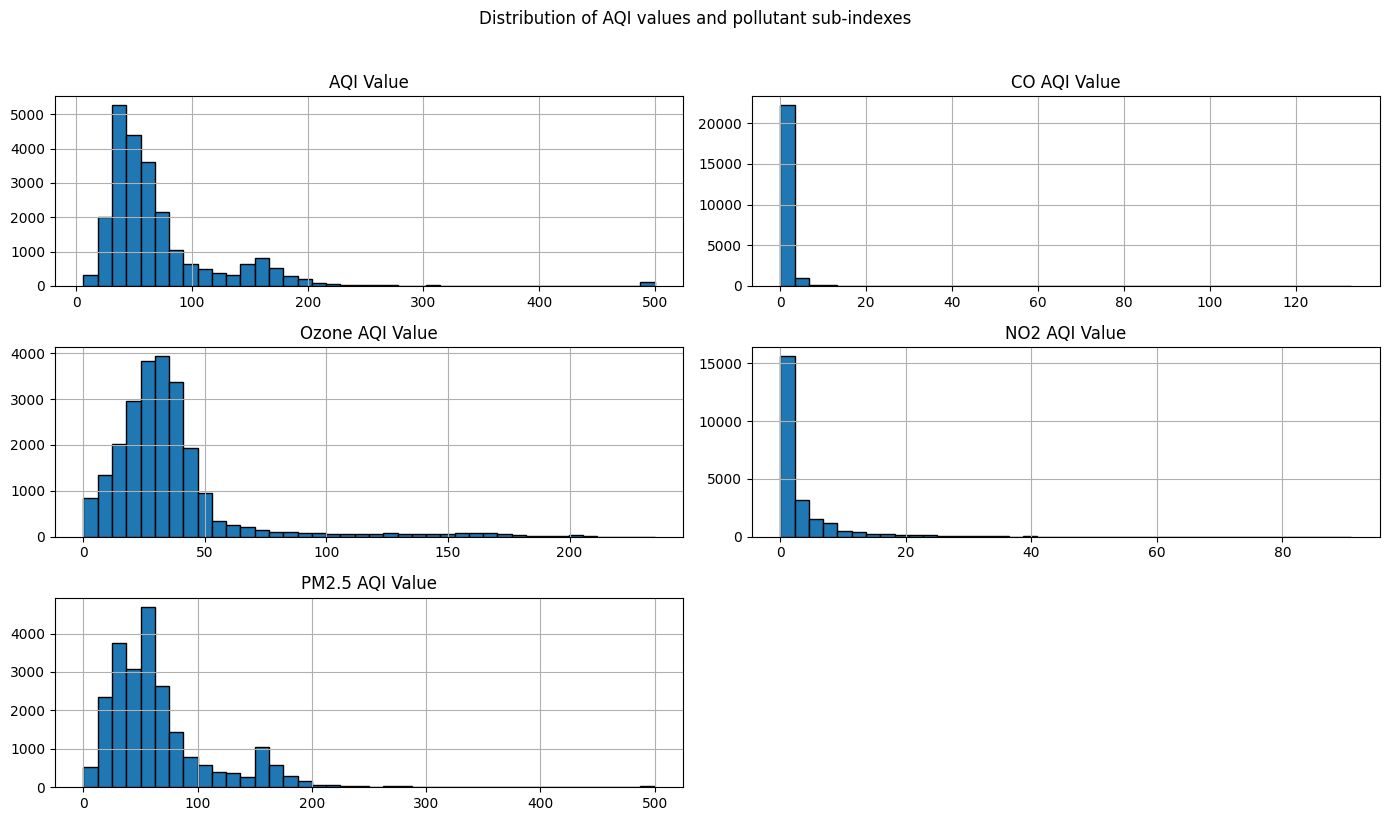

In [10]:
# Histogrammes
df[num_cols].hist(bins=40, figsize=(14, 8), edgecolor="black")
plt.suptitle("Distribution of AQI values and pollutant sub-indexes", y=1.02)
plt.tight_layout()
plt.show()

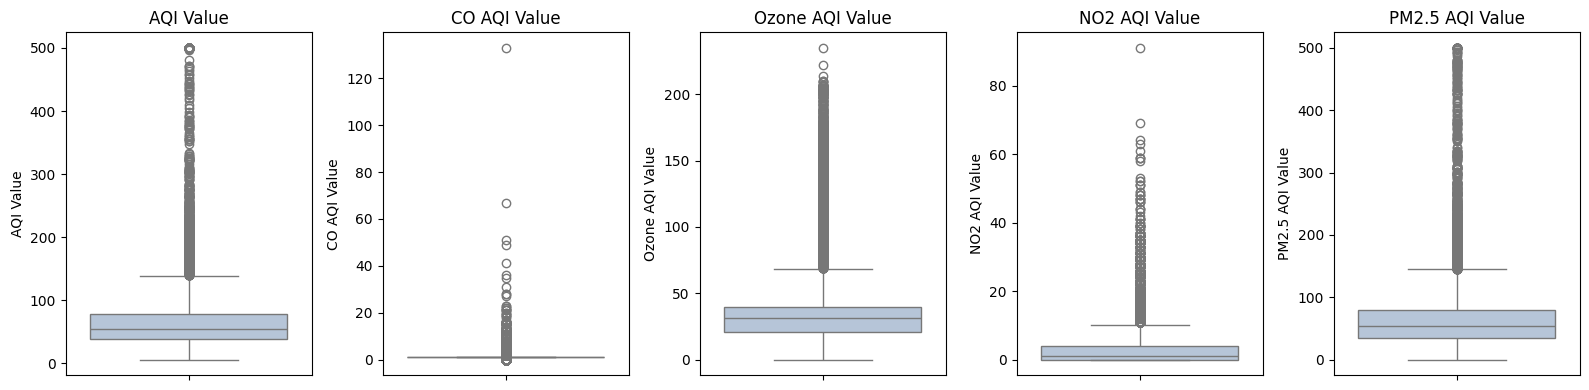

In [11]:
# Boxplots (un par variable, échelle indépendante)
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Descriptive statistics:** all variables range from 0 to 500 at most, which matches the standard AQI scale, and no negative or impossible value is present. The mean is systematically higher than the median (e.g. AQI: 72 vs 55), which indicates right-skewed distributions.

**Dominant pollutant:** `PM2.5 AQI Value` (mean 68.5, max 500) has a distribution almost identical to the overall `AQI Value` (mean 72.0, max 500). PM2.5 is therefore the main driver of the overall AQI.

**Low-variance sub-indexes:** `CO AQI Value` and `NO2 AQI Value` are concentrated near 0 (median of 1 for both, and 75 % of CO values equal to 1). They rarely drive the overall AQI and carry little variability.

**Distributions (histograms):** all variables are right-skewed. AQI and PM2.5 show a main peak around 40–60 and a secondary bump around 150–170, which suggests a group of highly polluted cities. Ozone is closer to a bell shape centered around 30.

**Outliers (boxplots):** all variables have many high outliers and none on the low side. They form a continuous series of points rather than isolated cases, so they correspond to genuine measurements in highly polluted cities rather than data entry errors.

**Decision:** outliers are **kept**. They are consistent with the AQI scale (0–500) and removing them would eliminate the most severe pollution cases (`Unhealthy`, `Hazardous`), which are precisely the cases a prediction model should learn to recognize.

**Scale difference:** the standard deviations differ a lot (≈1.8 for CO vs ≈56 for AQI), so normalization will be needed for scale-sensitive models (Logistic Regression, Perceptron, MLP).

In [12]:
counts = df["AQI Category"].value_counts()
props = df["AQI Category"].value_counts(normalize=True).round(3) * 100

display(pd.DataFrame({"count": counts, "percentage": props}))

,count,percentage
AQI Category,,
Good,9936,42.3
Moderate,9231,39.3
Unhealthy,2227,9.5
Unhealthy for Sensitive Groups,1591,6.8
Very Unhealthy,287,1.2
Hazardous,191,0.8


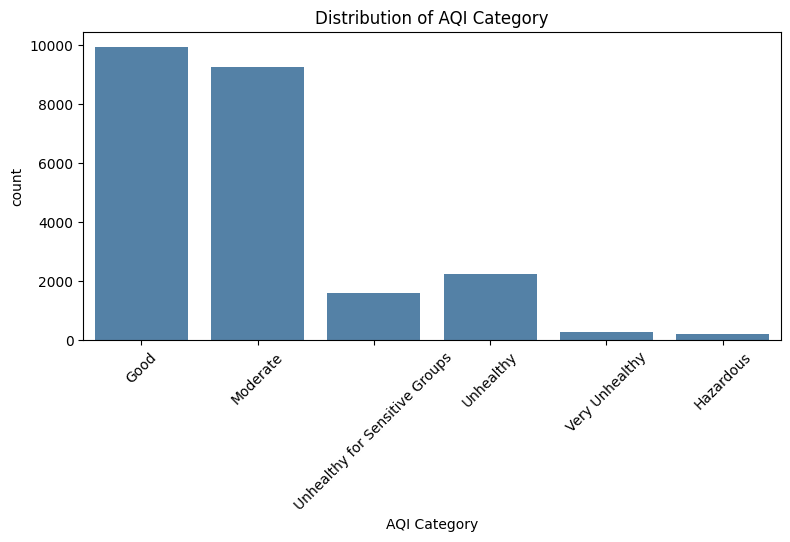

In [14]:
# Ordre logique des catégories (du moins au plus polluant)
order = ["Good", "Moderate", "Unhealthy for Sensitive Groups",
         "Unhealthy", "Very Unhealthy", "Hazardous"]
order = [c for c in order if c in df["AQI Category"].unique()]

plt.figure(figsize=(9, 4))
sns.countplot(data=df, x="AQI Category", order=order, color="steelblue")
plt.xticks(rotation=45)
plt.title("Distribution of AQI Category")
plt.show()

**Target distribution (`AQI Category`):** the classes are strongly imbalanced.
`Good` and `Moderate` together represent 81.6 % of the dataset, whereas `Very Unhealthy` and `Hazardous` represent only 2 %. The ratio between the largest and the smallest class is about 52:1.

**Consequences for the classification task:**
- A naive model always predicting `Good` would already reach 42.3 % accuracy, so accuracy alone is misleading. We will rely on **per-class precision, recall, F1-score** and the **macro-averaged F1**, as well as on confusion matrices.
- The train/test split will be **stratified** on `AQI Category` so that rare classes are represented in both sets.
- If rare classes are poorly predicted, class weighting (`class_weight="balanced"`) can be tested.

### 1.5 Multicollinearity

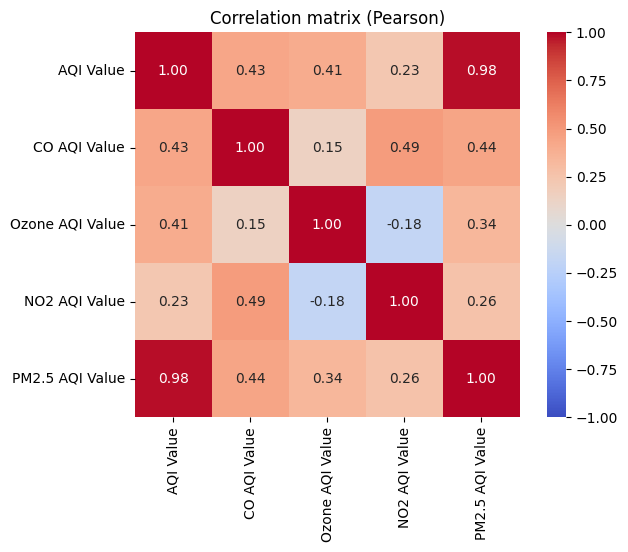

In [15]:
corr = df[num_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (Pearson)")
plt.show()

Multicollinearity was assessed with the Pearson correlation matrix.

**Correlation with the target (`AQI Value`):**
- `PM2.5 AQI Value`: r = 0.98 (almost perfect linear relationship)
- `CO AQI Value`: r = 0.43
- `Ozone AQI Value`: r = 0.41
- `NO2 AQI Value`: r = 0.23

**Correlation between predictors:** all pairwise correlations are low to moderate (the highest is CO–NO2 with r = 0.49, and Ozone–NO2 is slightly negative with r = -0.18). No pair of predictors is strongly correlated, so **there is no problematic multicollinearity** between the pollutant sub-indexes, and all of them can be kept as predictors.

**Comment:** the issue is not redundancy between predictors, but the fact that `PM2.5 AQI Value` is almost identical to the target. This is explained by the way the overall AQI is built: it seems to be the maximum of the sub-indexes, which is a non-linear relationship. This is why the correlations with CO, Ozone and NO2 are only moderate even though they sometimes determine the AQI. Tree-based models are expected to capture this relationship better than linear regression.

### 1.6 Checking the relationship between `AQI Value` and the sub-indexes

In [16]:
sub_cols = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]

# Maximum des 4 sous-indices pour chaque ligne
df["max_sub"] = df[sub_cols].max(axis=1)

# Comparaison avec l'AQI global
match = (df["AQI Value"] == df["max_sub"])
print(f"Lignes où AQI = max(sous-indices) : {match.sum()} / {len(df)} ({match.mean()*100:.2f} %)")

# Écart éventuel sur les lignes qui ne correspondent pas
display(df.loc[~match, ["AQI Value", "max_sub"] + sub_cols].head(10))

Lignes où AQI = max(sous-indices) : 23322 / 23463 (99.40 %)


,AQI Value,max_sub,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
276,500,466,1,38,1,466
417,444,391,2,111,1,391
439,303,260,1,48,0,260
453,356,284,1,60,0,284
470,500,464,1,40,0,464
598,434,362,1,53,1,362
620,500,443,1,43,0,443
644,500,376,1,40,0,376
690,390,335,1,54,1,335
702,500,493,1,49,1,493


In [17]:
sub_cols = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]

diff = df["AQI Value"] - df[sub_cols].max(axis=1)
mism = diff != 0

print("Nombre d'écarts :", mism.sum())
print("Tous positifs (AQI > max) ?", (diff[mism] > 0).all())

print("\nTaille de l'écart :")
display(diff[mism].describe().round(1))

print("PM2.5 sur les lignes en écart :")
display(df.loc[mism, "PM2.5 AQI Value"].describe().round(1))

print("Catégories AQI sur les lignes en écart :")
display(df.loc[mism, "AQI Category"].value_counts())

Nombre d'écarts : 141
Tous positifs (AQI > max) ? True

Taille de l'écart :


count    141.0
mean      55.9
std       34.4
min        2.0
25%       29.0
50%       53.0
75%       76.0
max      166.0
dtype: float64

PM2.5 sur les lignes en écart :


count    141.0
mean     383.4
std       76.6
min      208.0
25%      325.0
50%      386.0
75%      454.0
max      496.0
Name: PM2.5 AQI Value, dtype: float64

Catégories AQI sur les lignes en écart :


AQI Category
Hazardous         135
Very Unhealthy      6
Name: count, dtype: int64

We tested the hypothesis that the overall AQI is the maximum of the four pollutant sub-indexes.

**Result:** the hypothesis holds for **99.40 %** of the rows (23,322 / 23,463). The 141 remaining rows show a systematic pattern:
- the AQI is **always higher** than the maximum sub-index (mean gap ≈ 56 points, up to 166);
- `PM2.5 AQI Value` is always the maximum sub-index and is **very high** (≥ 208, median 386);
- these rows belong almost exclusively to the most severe categories (135 `Hazardous`, 6 `Very Unhealthy`).

**Interpretation:** the overall AQI is almost a deterministic function of the sub-indexes, but not exactly. The gaps are not random noise; they only appear for extreme PM2.5 values, which suggests that the overall AQI and the PM2.5 sub-index are computed slightly differently in that range (hypothesis, not verified with the data available).

**Consequences:**
- **Regression:** very high performance is expected, especially for tree-based models, with errors concentrated on extreme PM2.5 cases.
- **Classification:** about 71 % of the `Hazardous` rows (135 / 191) are affected, so the recall of this rare class will need particular attention.
- **Leakage:** `AQI Value` must not be used as a predictor of `AQI Category`, since the category is derived from it.
- These rows are valid measurements and are **kept**.

### 1.7 Data Cleaning

In [18]:
df_clean = df.copy()

# On garde les lignes (mesures valides) et on marque l'information absente
df_clean["Country"] = df_clean["Country"].fillna("Unknown")
df_clean["City"] = df_clean["City"].fillna("Unknown")

# Vérification
print("Valeurs manquantes restantes :", df_clean.isna().sum().sum())
print("Dimensions :", df_clean.shape)

Valeurs manquantes restantes : 0
Dimensions : (23463, 13)


In [21]:
print(df_clean.columns.tolist())

['Country', 'City', 'AQI Value', 'AQI Category', 'CO AQI Value', 'CO AQI Category', 'Ozone AQI Value', 'Ozone AQI Category', 'NO2 AQI Value', 'NO2 AQI Category', 'PM2.5 AQI Value', 'PM2.5 AQI Category', 'max_sub']


In [22]:
df_clean = df_clean.drop(columns="max_sub")
print("Dimensions :", df_clean.shape)   # attendu : (23463, 12)

Dimensions : (23463, 12)


The 427 missing `Country` values and the single missing `City` value were replaced by the label `"Unknown"`. The rows are **kept** because their pollutant measurements are valid, and no rows were dropped. These two columns are identifiers that will not be used as predictors, so this label has no effect on the models. No missing value remains.
The temporary column `max_sub` created for the hypothesis test was removed to avoid data leakage.


### 1.8 Encoding categorical variables

In [24]:
category_order = ["Good", "Moderate", "Unhealthy for Sensitive Groups",
                  "Unhealthy", "Very Unhealthy", "Hazardous"]

mapping = {cat: i for i, cat in enumerate(category_order)}
print(mapping)

df_clean["AQI Category Encoded"] = df_clean["AQI Category"].map(mapping)

# Vérifications
print("Valeurs manquantes après encodage :", df_clean["AQI Category Encoded"].isna().sum())
display(df_clean[["AQI Category", "AQI Category Encoded"]].drop_duplicates().sort_values("AQI Category Encoded"))

{'Good': 0, 'Moderate': 1, 'Unhealthy for Sensitive Groups': 2, 'Unhealthy': 3, 'Very Unhealthy': 4, 'Hazardous': 5}
Valeurs manquantes après encodage : 0


,AQI Category,AQI Category Encoded
1,Good,0
0,Moderate,1
9,Unhealthy for Sensitive Groups,2
12,Unhealthy,3
43,Very Unhealthy,4
180,Hazardous,5


Encoding is only needed for the **target of the classification task**, `AQI Category`. The other categorical columns do not need to be encoded:
- `Country` and `City` are high-cardinality geographic identifiers that will not be used as predictors (one-hot encoding would create thousands of columns and the models would learn locations rather than pollution levels).
- The sub-index categories (`CO`, `Ozone`, `NO2`, `PM2.5 AQI Category`) are derived directly from the corresponding numeric values, so they are redundant and are not used.

`AQI Category` has a natural severity order, so an **ordinal encoding** was applied manually (`Good` = 0, `Moderate` = 1, `Unhealthy for Sensitive Groups` = 2, `Unhealthy` = 3, `Very Unhealthy` = 4, `Hazardous` = 5). This preserves the order, unlike `LabelEncoder`, which would number the classes alphabetically. The original text column is kept next to the encoded one to display readable confusion matrices later.

### 1.9 Feature Selection 

In [25]:
features = ["CO AQI Value", "Ozone AQI Value", "NO2 AQI Value", "PM2.5 AQI Value"]

X = df_clean[features]
y_reg = df_clean["AQI Value"]               # cible de régression
y_clf = df_clean["AQI Category Encoded"]    # cible de classification

print("X       :", X.shape)
print("y_reg   :", y_reg.shape)
print("y_clf   :", y_clf.shape)

X       : (23463, 4)
y_reg   : (23463,)
y_clf   : (23463,)


The predictors are the four pollutant sub-indexes: `CO AQI Value`, `Ozone AQI Value`, `NO2 AQI Value` and `PM2.5 AQI Value`. They are the components from which the overall AQI is built, and the correlation analysis showed no problematic multicollinearity between them. CO and NO2 have a low variance but are kept, since they can occasionally determine the overall AQI and keeping them has no cost.

**Excluded variables:**
- `Country`, `City`: high-cardinality identifiers, not related to the pollutant levels themselves.
- The sub-index categories: redundant with the corresponding numeric values.
- `AQI Category` / `AQI Category Encoded`: these are targets, not predictors.
- `AQI Value` is the target of the regression task, and it is **excluded from the classification predictors** because the category is derived from it (data leakage).

The same feature matrix `X` is used for both tasks, with two different targets: `AQI Value` (regression) and `AQI Category Encoded` (classification).

### 1.10 Data Splitting

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)

Train : (18770, 4)
Test  : (4693, 4)


In [27]:
check = pd.DataFrame({
    "train (%)": (y_clf_train.value_counts(normalize=True) * 100).round(2),
    "test (%)":  (y_clf_test.value_counts(normalize=True) * 100).round(2),
    "train (n)": y_clf_train.value_counts(),
    "test (n)":  y_clf_test.value_counts(),
}).sort_index()
display(check)

,train (%),test (%),train (n),test (n)
AQI Category Encoded,,,,
0,42.35,42.34,7949,1987
1,39.34,39.34,7385,1846
2,6.78,6.78,1273,318
3,9.49,9.50,1781,446
4,1.22,1.24,229,58
5,0.82,0.81,153,38


The dataset was split into a training set (80 %, 18,770 rows) and a test set (20 %, 4,693 rows) with `train_test_split` (`random_state=42` for reproducibility).

The split is **stratified on `AQI Category`**, because the classes are strongly imbalanced. The check shows that class proportions are almost identical in both sets (e.g. `Good`: 42.35 % vs 42.34 %), and that the rarest class `Hazardous` is present in both (153 rows in train, 38 in test).

The regression and classification targets are split **together**, so both tasks use exactly the same train and test rows, which makes the comparison between models consistent.

The split is done **before** normalization so that no information from the test set leaks into the preprocessing.

### 1.11 Normalization

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit uniquement sur le train : le scaler apprend moyenne et écart-type du train
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# transform seulement sur le test : on réutilise les paramètres du train
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Vérification
print("Train normalisé (moyenne ~ 0, écart-type ~ 1) :")
display(X_train_scaled.describe().loc[["mean", "std"]].round(3))

print("Test normalisé (proche de 0 et 1, mais pas exact) :")
display(X_test_scaled.describe().loc[["mean", "std"]].round(3))

Train normalisé (moyenne ~ 0, écart-type ~ 1) :


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
mean,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


Test normalisé (proche de 0 et 1, mais pas exact) :


,CO AQI Value,Ozone AQI Value,NO2 AQI Value,PM2.5 AQI Value
mean,0.009,0.012,0.020,-0.001
std,0.892,1.041,1.029,0.990


The numeric predictors were standardized with `StandardScaler` (zero mean, unit variance). We chose standardization rather than min-max scaling because outliers are kept in the data, and min-max scaling would compress most of the values near 0 because of the extreme points (up to 500).

**Avoiding data leakage:** the scaler is **fitted on the training set only** and then applied to the test set, so no information from the test set is used during preprocessing.

**Check:** on the training set, the mean is 0 and the standard deviation is 1 for all four features. On the test set, the values are close but not identical (e.g. standard deviation of 0.89 for CO), as expected. The gap is largest for CO, which is almost constant with a few extreme values.

**Which models use which version:**
- **Scaled features:** Linear Regression, Logistic Regression, Perceptron, MLP (sensitive to feature scales).
- **Original features:** Decision Tree and Random Forest, which are scale-invariant and remain easier to interpret in AQI units.

## 2. Air Quality (AQI Values) Prediction (Regression Task)
**Goal:** Predict	the	overall	AQI	Value	based	on	pollutant	sub-index	values	and	other	relevant variables.	Add	comments	if	needed	to	interpret	your	choices	and	results	

### 2.1 Variable Selection

In [29]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Vérification des données de la régression
print("Prédicteurs :", features)
print("Cible       : AQI Value")
print("Train :", X_train.shape, "| Test :", X_test.shape)

# 2. Corrélation de chaque prédicteur avec la cible (sur le TRAIN uniquement)
corr_target = X_train.join(y_reg_train).corr()["AQI Value"].drop("AQI Value")
print("\nCorrélation avec AQI Value (train) :")
print(corr_target.sort_values(ascending=False).round(3))

# 3. Baseline : prédire toujours la moyenne du train
y_baseline = np.full(len(y_reg_test), y_reg_train.mean())
print("\nBaseline (prédiction = moyenne du train) :")
print(f"R²   : {r2_score(y_reg_test, y_baseline):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_reg_test, y_baseline)):.2f}")
print(f"MAE  : {mean_absolute_error(y_reg_test, y_baseline):.2f}")

Prédicteurs : ['CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']
Cible       : AQI Value
Train : (18770, 4) | Test : (4693, 4)

Corrélation avec AQI Value (train) :
PM2.5 AQI Value    0.985
CO AQI Value       0.427
Ozone AQI Value    0.405
NO2 AQI Value      0.235
Name: AQI Value, dtype: float64

Baseline (prédiction = moyenne du train) :
R²   : -0.0000
RMSE : 55.96
MAE  : 36.83


**Target:** `AQI Value`

**Predictors:** `CO AQI Value`, `Ozone AQI Value`, `NO2 AQI Value`, `PM2.5 AQI Value`

**Justification:**
- The overall AQI is built from the four pollutant sub-indexes, so they are the natural predictors.
- On the training set, `PM2.5 AQI Value` is almost perfectly correlated with the target (0.985). `CO` (0.43) and `Ozone` (0.41) are moderately correlated, and `NO2` (0.24) is weakly correlated. All four carry some information, so we keep them.
- The predictors are not strongly correlated with each other (highest: CO–NO2 = 0.49), so multicollinearity is not a problem.
- `Country` and `City` are excluded: they have high cardinality and no direct link with the AQI value.
- The `AQI Category` columns are excluded: they are redundant with the numeric values.

**Baseline:** predicting the training mean for every observation gives R² = 0.00, RMSE = 55.96 and MAE = 36.83. These are the scores that the models must beat.

### 2.3 Linear Regression

                            0
Model       Linear Regression
R² train               0.9752
R² test                0.9719
RMSE train             8.8251
RMSE test              9.3846
MAE train              4.8077
MAE test               4.9266

Intercept : 71.98
Coefficients :
PM2.5 AQI Value    53.735
Ozone AQI Value     4.377
CO AQI Value        0.101
NO2 AQI Value      -0.179
dtype: float64


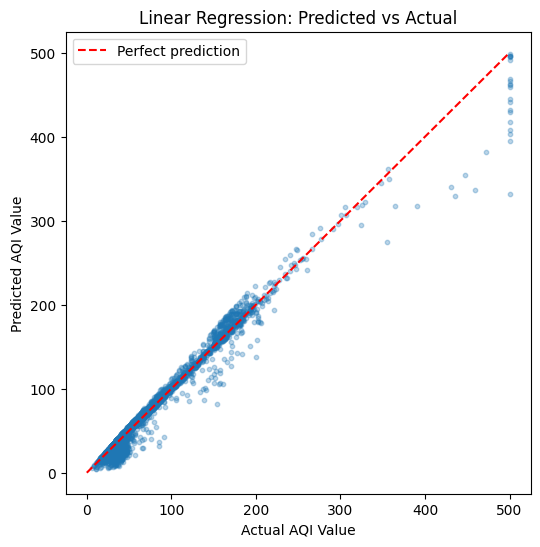

In [30]:
from sklearn.linear_model import LinearRegression

# 1. Entraînement (données normalisées)
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_reg_train)

# 2. Prédictions
y_pred_lin_train = lin_reg.predict(X_train_scaled)
y_pred_lin_test = lin_reg.predict(X_test_scaled)

# 3. Métriques
def evaluate(name, y_train, pred_train, y_test, pred_test):
    return {
        "Model": name,
        "R² train": r2_score(y_train, pred_train),
        "R² test": r2_score(y_test, pred_test),
        "RMSE train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE test": np.sqrt(mean_squared_error(y_test, pred_test)),
        "MAE train": mean_absolute_error(y_train, pred_train),
        "MAE test": mean_absolute_error(y_test, pred_test),
    }

results = []
results.append(evaluate("Linear Regression", y_reg_train, y_pred_lin_train,
                        y_reg_test, y_pred_lin_test))
print(pd.DataFrame(results).round(4).T)

# 4. Coefficients (variables normalisées, donc comparables entre eux)
coefs = pd.Series(lin_reg.coef_, index=features).sort_values(ascending=False)
print("\nIntercept :", round(lin_reg.intercept_, 2))
print("Coefficients :")
print(coefs.round(3))

# 5. Graphique prédit vs réel
plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, y_pred_lin_test, alpha=0.3, s=10)
lims = [0, 500]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual AQI Value")
plt.ylabel("Predicted AQI Value")
plt.title("Linear Regression: Predicted vs Actual")
plt.legend()
plt.show()

The model was trained on the standardized predictors.

| Metric | Train | Test |
|---|---|---|
| R² | 0.9752 | 0.9719 |
| RMSE | 8.83 | 9.38 |
| MAE | 4.81 | 4.93 |

**Results:**
- The model clearly beats the baseline (RMSE 55.96 → 9.38). It explains about 97% of the variance of the AQI.
- Train and test scores are almost identical, so there is no overfitting. The model is simple (5 parameters) and the training set is large.
- `PM2.5 AQI Value` has by far the largest coefficient (53.7 per standard deviation), followed by `Ozone` (4.4). `CO` and `NO2` have almost no effect. The small negative `NO2` coefficient has no physical meaning and is probably due to its correlation with `CO`.

**Limits:**
- The overall AQI is (almost) the maximum of the four sub-indexes, which is not a linear relationship.
- The predicted vs actual plot shows that the model underestimates the very high AQI values (around 500), and is slightly less accurate for low AQI values where a pollutant other than PM2.5 dominates.
- The RMSE (9.38) is about twice the MAE (4.93): most errors are small, but a few large errors on extreme values increase the RMSE.
- This is a case of **high bias**: the linear form is too simple for the true relationship. Non-linear models should do better.

### 2.4 Decision Tree Regressor

                         R² train  R² test  RMSE train  RMSE test  MAE train  \
Model                                                                          
Linear Regression          0.9752   0.9719      8.8251     9.3846     4.8077   
Decision Tree (full)       1.0000   0.9971      0.0000     3.0158     0.0000   
Decision Tree (depth 8)    0.9971   0.9943      3.0250     4.2172     1.0564   

                         MAE test  
Model                              
Linear Regression          4.9266  
Decision Tree (full)       0.2259  
Decision Tree (depth 8)    1.1986  

Profondeur de l'arbre complet : 18
Nombre de feuilles (arbre complet) : 879


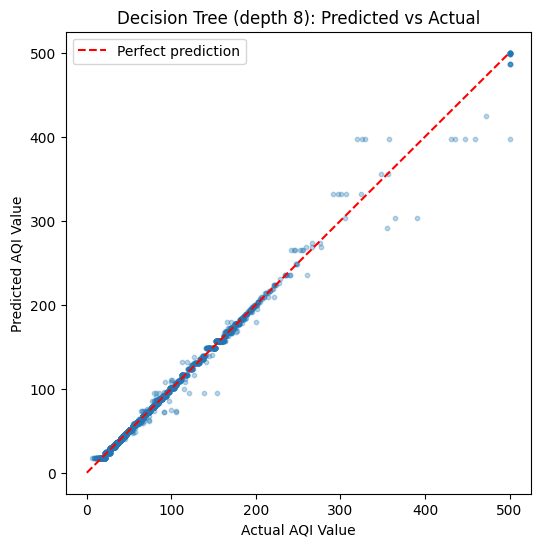

In [31]:
from sklearn.tree import DecisionTreeRegressor

# 1. Arbre sans contrainte
dt_full = DecisionTreeRegressor(random_state=42)
dt_full.fit(X_train, y_reg_train)

# 2. Arbre contraint
dt_reg = DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=42)
dt_reg.fit(X_train, y_reg_train)

# 3. Métriques (on réutilise la fonction evaluate et la liste results)
for name, model in [("Decision Tree (full)", dt_full),
                    ("Decision Tree (depth 8)", dt_reg)]:
    results.append(evaluate(name,
                            y_reg_train, model.predict(X_train),
                            y_reg_test, model.predict(X_test)))

print(pd.DataFrame(results).set_index("Model").round(4))
print("\nProfondeur de l'arbre complet :", dt_full.get_depth())
print("Nombre de feuilles (arbre complet) :", dt_full.get_n_leaves())

# 4. Graphique prédit vs réel (arbre contraint)
y_pred_dt_test = dt_reg.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, y_pred_dt_test, alpha=0.3, s=10)
plt.plot([0, 500], [0, 500], "r--", label="Perfect prediction")
plt.xlabel("Actual AQI Value")
plt.ylabel("Predicted AQI Value")
plt.title("Decision Tree (depth 8): Predicted vs Actual")
plt.legend()
plt.show()

Trees are scale-invariant, so they were trained on the original (non-standardized) data. Two versions were compared to illustrate overfitting: a fully grown tree and a constrained tree (`max_depth=8`, `min_samples_leaf=10`).

| Model | R² train | R² test | RMSE train | RMSE test | MAE train | MAE test |
|---|---|---|---|---|---|---|
| Linear Regression | 0.9752 | 0.9719 | 8.83 | 9.38 | 4.81 | 4.93 |
| Decision Tree (depth 8) | 0.9971 | 0.9943 | 3.03 | 4.22 | 1.06 | 1.20 |
| Decision Tree (full) | 1.0000 | 0.9971 | 0.00 | 3.02 | 0.00 | 0.23 |

**Results:**
- Both trees clearly outperform Linear Regression (test RMSE divided by 2 to 3). This confirms that the AQI is a non-linear function (a maximum) of the sub-indexes, which trees capture well with their thresholds.
- The fully grown tree (depth 18, 879 leaves) fits the training set perfectly (R² = 1, RMSE = 0). There is a train/test gap, which is a sign of **high variance**, but the test performance is still the best (R² = 0.9971). The relationship is almost deterministic, so the memorized rules are real patterns and not noise.
- The constrained tree has a smaller train/test gap but a slightly lower test accuracy: limiting the depth adds some bias, and the rare cases (another pollutant dominating, extreme values) are less well captured.
- The predicted vs actual plot is very close to the diagonal. The remaining errors are concentrated on the highest AQI values (300–500), where there are only a few training examples.

**Bias–variance summary:** Linear Regression has high bias and low variance; the full tree has low bias and higher variance; the constrained tree is in between.

### 2.5 Random Forest Regressor

                         R² train  R² test  RMSE train  RMSE test  MAE train  \
Model                                                                          
Linear Regression          0.9752   0.9719      8.8251     9.3846     4.8077   
Decision Tree (full)       1.0000   0.9971      0.0000     3.0158     0.0000   
Decision Tree (depth 8)    0.9971   0.9943      3.0250     4.2172     1.0564   
Random Forest              0.9998   0.9979      0.8790     2.5792     0.0719   

                         MAE test  
Model                              
Linear Regression          4.9266  
Decision Tree (full)       0.2259  
Decision Tree (depth 8)    1.1986  
Random Forest              0.2235  

Feature importances :
                 Random Forest  Decision Tree (full)
PM2.5 AQI Value         0.9808                0.9804
Ozone AQI Value         0.0180                0.0182
CO AQI Value            0.0007                0.0008
NO2 AQI Value           0.0005                0.0006


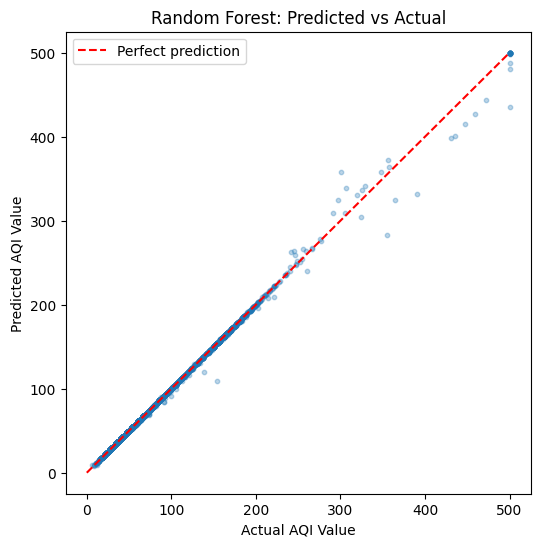


Erreur absolue moyenne par tranche d'AQI réel (RF) :
            count   mean    max
actual                         
(0, 50]      1987   0.01   3.22
(50, 100]    1859   0.05   8.23
(100, 200]    751   0.21  45.22
(200, 300]     58   3.14  27.87
(300, 500]     38  15.98  72.26


In [32]:
from sklearn.ensemble import RandomForestRegressor

# 1. Entraînement
rf_reg = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_reg_train)

# 2. Métriques
y_pred_rf_train = rf_reg.predict(X_train)
y_pred_rf_test = rf_reg.predict(X_test)
results.append(evaluate("Random Forest", y_reg_train, y_pred_rf_train,
                        y_reg_test, y_pred_rf_test))
print(pd.DataFrame(results).set_index("Model").round(4))

# 3. Importance des variables (RF et arbre complet)
importances = pd.DataFrame({
    "Random Forest": rf_reg.feature_importances_,
    "Decision Tree (full)": dt_full.feature_importances_,
}, index=features).sort_values("Random Forest", ascending=False)
print("\nFeature importances :")
print(importances.round(4))

# 4. Graphique prédit vs réel
plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, y_pred_rf_test, alpha=0.3, s=10)
plt.plot([0, 500], [0, 500], "r--", label="Perfect prediction")
plt.xlabel("Actual AQI Value")
plt.ylabel("Predicted AQI Value")
plt.title("Random Forest: Predicted vs Actual")
plt.legend()
plt.show()

# 5. Où sont les plus grosses erreurs ? (RF)
errors = pd.DataFrame({"actual": y_reg_test, "pred": y_pred_rf_test})
errors["abs_err"] = (errors["actual"] - errors["pred"]).abs()
print("\nErreur absolue moyenne par tranche d'AQI réel (RF) :")
print(errors.groupby(pd.cut(errors["actual"], [0, 50, 100, 200, 300, 500]),
                     observed=True)["abs_err"].agg(["count", "mean", "max"]).round(2))

A Random Forest (200 trees) was trained on the original data. It averages many fully grown trees built on bootstrap samples, which reduces the variance of a single tree while keeping its low bias.

| Model | R² train | R² test | RMSE train | RMSE test | MAE train | MAE test |
|---|---|---|---|---|---|---|
| Linear Regression | 0.9752 | 0.9719 | 8.83 | 9.38 | 4.81 | 4.93 |
| Decision Tree (depth 8) | 0.9971 | 0.9943 | 3.03 | 4.22 | 1.06 | 1.20 |
| Decision Tree (full) | 1.0000 | 0.9971 | 0.00 | 3.02 | 0.00 | 0.23 |
| Random Forest | 0.9998 | 0.9979 | 0.88 | 2.58 | 0.07 | 0.22 |

**Results:**
- The Random Forest is the best regression model (test R² = 0.9979, RMSE = 2.58).
- Compared with the full tree, the MAE is the same (0.22), but the RMSE is lower (3.02 → 2.58). The forest mainly reduces the large errors, which is the effect of averaging many trees (lower variance).
- The training scores of a forest are optimistic because each tree has seen part of the training data, so the test scores are the ones to rely on.
- The predicted vs actual plot is almost on the diagonal. The remaining errors are on the highest AQI values (300–500), where there are very few training examples.

**Feature importance:**
- `PM2.5 AQI Value` accounts for 98% of the importance, `Ozone` for 1.8%, and `CO` and `NO2` for less than 0.1%. The tree and the forest give the same ranking.
- This is consistent with the correlations and with the linear coefficients. CO and NO2 sub-indexes are usually small, so they are rarely the maximum that determines the AQI.
- Impurity-based importance shows how much the model uses a variable, not a causal effect.

### 2.6 Model Comparison and Discussion


                         R² test  RMSE test  MAE test  RMSE gap (test - train)
Model                                                                         
Linear Regression          0.972      9.385     4.927                    0.559
Decision Tree (full)       0.997      3.016     0.226                    3.016
Decision Tree (depth 8)    0.994      4.217     1.199                    1.192
Random Forest              0.998      2.579     0.224                    1.700


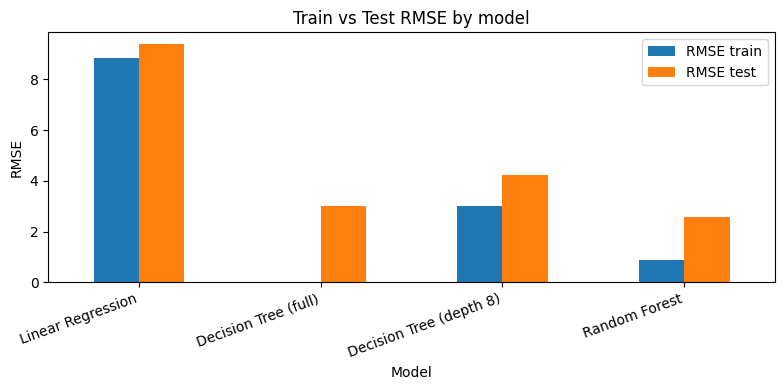

In [33]:
# 1. Tableau récapitulatif avec l'écart train/test
summary = pd.DataFrame(results).set_index("Model")
summary["RMSE gap (test - train)"] = summary["RMSE test"] - summary["RMSE train"]
print(summary[["R² test", "RMSE test", "MAE test", "RMSE gap (test - train)"]].round(3))

# 2. RMSE train vs test par modèle
summary[["RMSE train", "RMSE test"]].plot(kind="bar", figsize=(8, 4))
plt.ylabel("RMSE")
plt.title("Train vs Test RMSE by model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

| Model | Test R² | Test RMSE | Test MAE | RMSE gap (test − train) |
|---|---|---|---|---|
| Linear Regression | 0.972 | 9.38 | 4.93 | 0.56 |
| Decision Tree (depth 8) | 0.994 | 4.22 | 1.20 | 1.19 |
| Decision Tree (full) | 0.997 | 3.02 | 0.23 | 3.02 |
| Random Forest | **0.998** | **2.58** | **0.22** | 1.70 |

**Best model:** the Random Forest has the best test scores on all three metrics, followed closely by the fully grown Decision Tree. Linear Regression is clearly behind, although it still explains 97% of the variance.

**Bias and variance:**
- **Linear Regression** has high bias: its training and test errors are both high and almost equal (RMSE 8.83 vs 9.38). The linear form cannot represent a relationship that is a maximum of several sub-indexes.
- **The fully grown Decision Tree** has very low bias but higher variance: it fits the training set perfectly (RMSE = 0) and the gap with the test set is the largest (3.02).
- **The constrained Decision Tree** reduces the gap, but the extra bias makes it less accurate on the test set.
- **The Random Forest** keeps the low bias of deep trees and reduces variance by averaging 200 trees, which lowers the large errors and gives the best test RMSE.

**Overfitting:** a large train/test gap does not always mean a bad model. The fully grown tree has the largest gap but still generalizes much better than the linear model. The relationship between the sub-indexes and the AQI is almost deterministic and the dataset is large and low-noise, so the learned rules are real patterns and not noise. On noisier data, an unconstrained tree would be more likely to overfit.

**Model complexity:** more flexible models (linear → tree → forest) gave better test performance here, because the main limitation was bias, not variance.

**Remaining limitation:** all models are less accurate for AQI values above 300. There are few training examples in this range, and the overall AQI appears to be computed differently from the PM2.5 sub-index for extreme PM2.5 values.

**Feature importance:** `PM2.5 AQI Value` explains about 98% of the importance, `Ozone` 1.8%, while `CO` and `NO2` are negligible.

## 3. Air Quality Category Prediction (Classification Task)
**Goal:** Predict	the	AQI	Category	using	pollutant	values.	

### 3.1 Variable Selection and Baseline

Predictors: ['CO AQI Value', 'Ozone AQI Value', 'NO2 AQI Value', 'PM2.5 AQI Value']
Target    : AQI Category Encoded (0 = Good ... 5 = Hazardous)

                                train (%)  test (%)  train (n)  test (n)
Good                                42.35     42.34       7949      1987
Moderate                            39.34     39.34       7385      1846
Unhealthy for Sensitive Groups       6.78      6.78       1273       318
Unhealthy                            9.49      9.50       1781       446
Very Unhealthy                       1.22      1.24        229        58
Hazardous                            0.82      0.81        153        38 

                                CO AQI Value  Ozone AQI Value  NO2 AQI Value  \
Good                                     0.8             28.3            1.5   
Moderate                                 1.3             31.4            3.6   
Unhealthy for Sensitive Groups           2.1             41.7            5.3   
Unhealthy           

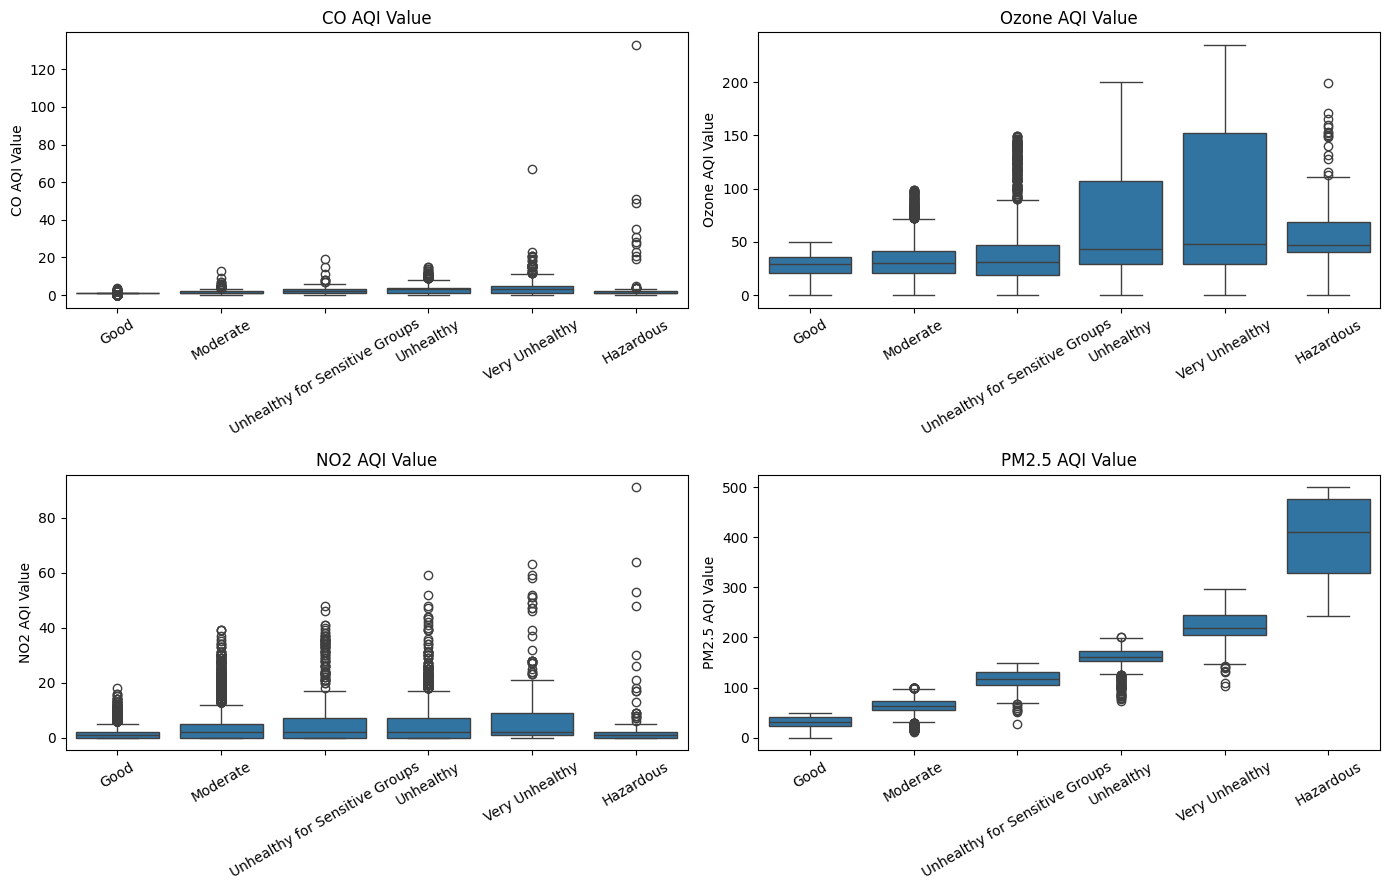

Baseline accuracy : 0.4234
Baseline macro-F1 : 0.0992
                                precision    recall  f1-score   support

                          Good       0.42      1.00      0.59      1987
                      Moderate       0.00      0.00      0.00      1846
Unhealthy for Sensitive Groups       0.00      0.00      0.00       318
                     Unhealthy       0.00      0.00      0.00       446
                Very Unhealthy       0.00      0.00      0.00        58
                     Hazardous       0.00      0.00      0.00        38

                      accuracy                           0.42      4693
                     macro avg       0.07      0.17      0.10      4693
                  weighted avg       0.18      0.42      0.25      4693



In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# --- 1. Prédicteurs retenus ---
print("Predictors:", features)
print("Target    : AQI Category Encoded (0 = Good ... 5 = Hazardous)\n")

# --- 2. Répartition des classes : train vs test ---
dist = pd.DataFrame({
    "train (%)": y_clf_train.value_counts(normalize=True).sort_index() * 100,
    "test (%)":  y_clf_test.value_counts(normalize=True).sort_index() * 100,
    "train (n)": y_clf_train.value_counts().sort_index(),
    "test (n)":  y_clf_test.value_counts().sort_index(),
})
dist.index = category_order
print(dist.round(2), "\n")

# --- 3. Moyenne des sous-indices par catégorie (train) ---
means = X_train.groupby(y_clf_train).mean()
means.index = category_order
print(means.round(1), "\n")

# --- 4. Boxplots des 4 sous-indices par catégorie ---
plot_df = X_train.copy()
plot_df["Category"] = y_clf_train.map(dict(enumerate(category_order)))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=plot_df, x="Category", y=col, order=category_order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

# --- 5. Baseline : toujours prédire la classe majoritaire (Good) ---
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_clf_train)
pred_base = baseline.predict(X_test)

print("Baseline accuracy :", round(accuracy_score(y_clf_test, pred_base), 4))
print("Baseline macro-F1 :", round(f1_score(y_clf_test, pred_base, average="macro", zero_division=0), 4))
print(classification_report(y_clf_test, pred_base, target_names=category_order, zero_division=0))

**Predictors.** We use the four pollutant sub-indexes: `CO AQI Value`, `Ozone AQI Value`, `NO2 AQI Value` and `PM2.5 AQI Value`. The target is `AQI Category Encoded` (0 = Good, ..., 5 = Hazardous).

**Why these variables.** The AQI category comes from the overall AQI, which is computed from these four sub-indexes. `AQI Value` is excluded because it would cause data leakage. `Country`, `City` and the sub-index categories are excluded because they are not useful or are redundant.

**What the data shows.**
- PM2.5 increases clearly from Good (31.6) to Hazardous (402.2) and its classes barely overlap. It carries most of the information.
- Ozone adds some information for the Unhealthy classes.
- CO and NO2 are close to 0 and overlap a lot, so they are weak predictors.

**Class imbalance.** Train and test have the same class proportions thanks to stratification. `Very Unhealthy` and `Hazardous` have only 58 and 38 test examples, so their scores will be noisy.

**Baseline.** Always predicting `Good` gives an accuracy of 0.4234 but a macro-F1 of only 0.0992. Accuracy alone is misleading, so we will mainly use the macro-F1 and the per-class scores.

### 3.2 Logistic Regression

                                Accuracy train  Accuracy test  \
Model                                                           
Logistic Regression                     0.9388         0.9452   
Logistic Regression (balanced)          0.9245         0.9320   

                                Precision (macro)  Recall (macro)  F1 (macro)  \
Model                                                                           
Logistic Regression                        0.9356          0.8824      0.9034   
Logistic Regression (balanced)             0.8521          0.9272      0.8799   

                                F1 (weighted)  Recall Hazardous  
Model                                                            
Logistic Regression                    0.9445            0.9737  
Logistic Regression (balanced)         0.9337            1.0000   

Logistic Regression
                                precision    recall  f1-score   support

                          Good       0.97      0.95    

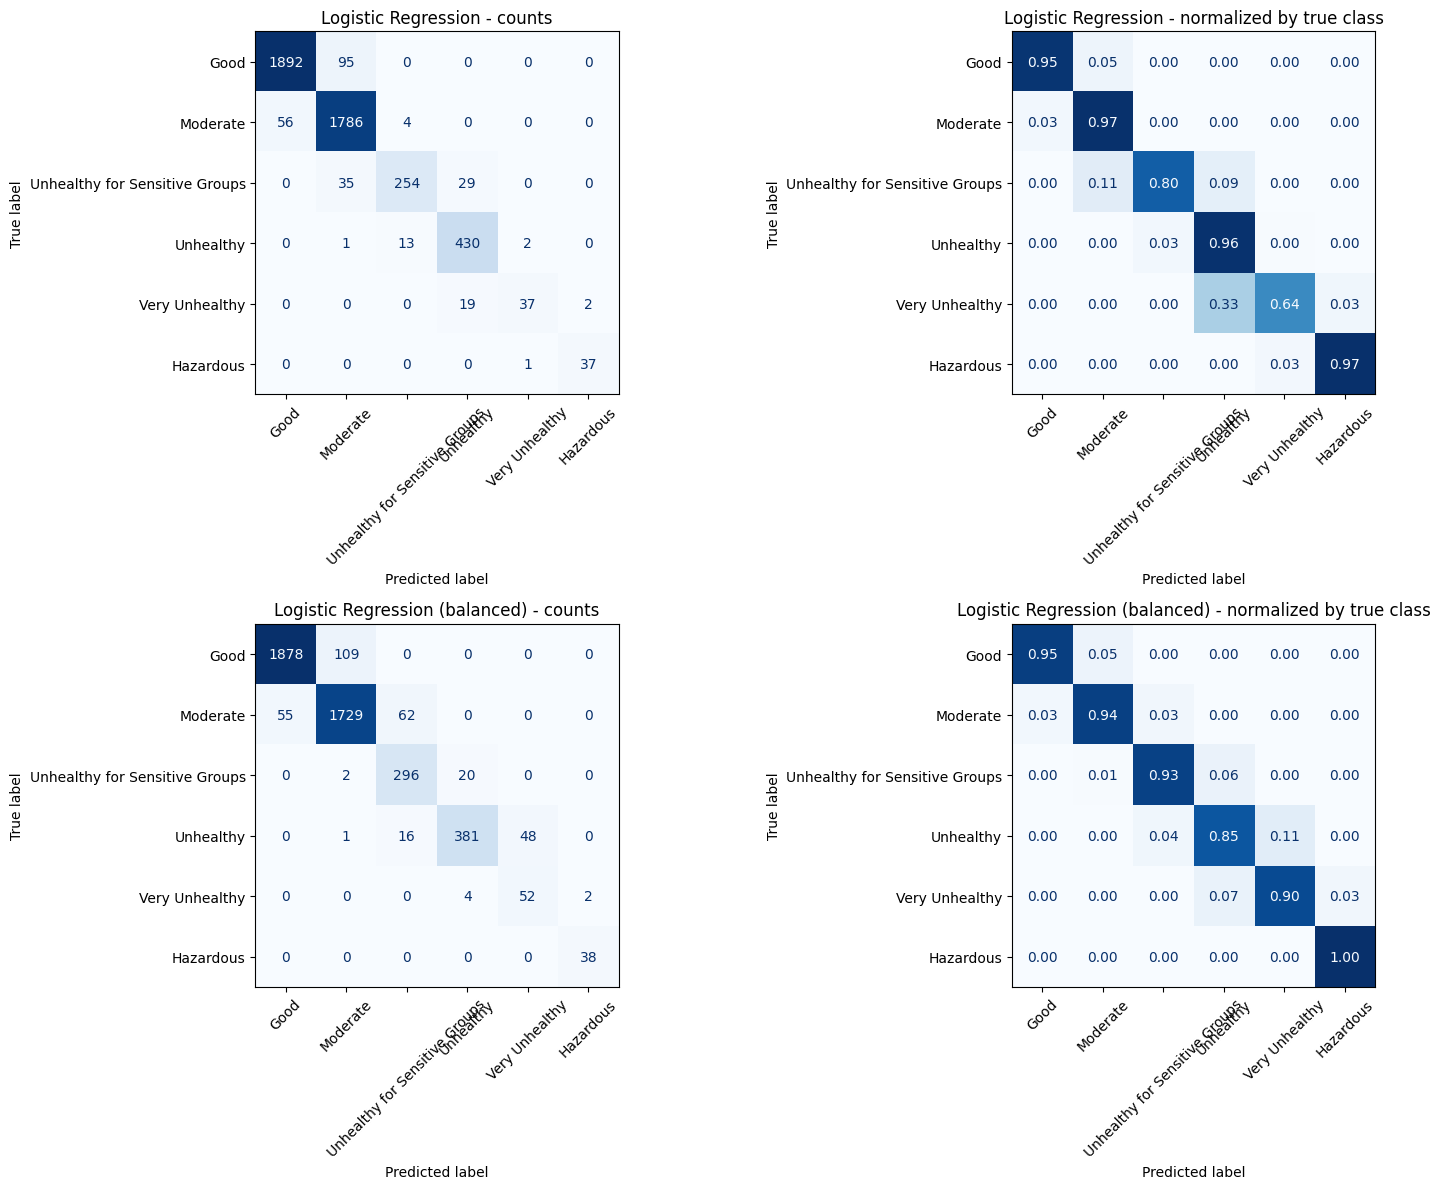

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# --- Fonction d'évaluation réutilisable pour tous les classifieurs ---
def evaluate_clf(name, y_train, pred_train, y_test, pred_test):
    return {
        "Model": name,
        "Accuracy train": accuracy_score(y_train, pred_train),
        "Accuracy test": accuracy_score(y_test, pred_test),
        "Precision (macro)": precision_score(y_test, pred_test, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred_test, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred_test, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, pred_test, average="weighted", zero_division=0),
        "Recall Hazardous": recall_score(y_test, pred_test, labels=[5], average=None, zero_division=0)[0],
    }

clf_results = []

# --- Entraînement des deux versions (données normalisées) ---
log_std = LogisticRegression(max_iter=1000, random_state=42)
log_std.fit(X_train_scaled, y_clf_train)

log_bal = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_bal.fit(X_train_scaled, y_clf_train)

models = [("Logistic Regression", log_std),
          ("Logistic Regression (balanced)", log_bal)]

preds = {}
for name, model in models:
    pred_tr = model.predict(X_train_scaled)
    pred_te = model.predict(X_test_scaled)
    preds[name] = pred_te
    clf_results.append(evaluate_clf(name, y_clf_train, pred_tr, y_clf_test, pred_te))

# --- Tableau récapitulatif ---
print(pd.DataFrame(clf_results).set_index("Model").round(4), "\n")

# --- Rapport détaillé par classe (test) ---
for name, _ in models:
    print("=" * 70)
    print(name)
    print(classification_report(y_clf_test, preds[name],
                                target_names=category_order, zero_division=0))

# --- Matrices de confusion (valeurs brutes + normalisées par ligne) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for i, (name, _) in enumerate(models):
    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds[name], display_labels=category_order,
        ax=axes[i, 0], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes[i, 0].set_title(f"{name} - counts")

    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds[name], display_labels=category_order,
        normalize="true", values_format=".2f",
        ax=axes[i, 1], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes[i, 1].set_title(f"{name} - normalized by true class")
plt.tight_layout()
plt.show()

We trained two Logistic Regression models on the standardized data: a standard one and one with `class_weight="balanced"`.

**Results.**

| Model | Accuracy test | Macro-F1 | Macro recall | Macro precision |
|---|---|---|---|---|
| Logistic Regression | 0.9452 | 0.9034 | 0.8824 | 0.9356 |
| Logistic Regression (balanced) | 0.9320 | 0.8799 | 0.9272 | 0.8521 |

**Observations.**
- Both models are far above the baseline (accuracy 0.42, macro-F1 0.10).
- There is no overfitting: train and test accuracy are very close. The model has high bias and low variance, like the linear regression in Part 2.
- Most errors are between neighbouring classes (for example Good / Moderate). Very serious mistakes, such as Good predicted as Hazardous, never happen.
- The standard model is weakest on `Very Unhealthy` (recall 0.64): a third of these cases are predicted as `Unhealthy`.

**Effect of `class_weight="balanced"`.**
- Recall improves for the rare classes: `Very Unhealthy` goes from 0.64 to 0.90 and `Hazardous` reaches 1.00.
- Precision drops and `Unhealthy` recall falls from 0.96 to 0.85, because more cases are pushed to `Very Unhealthy`. The errors are moved, not removed.
- Overall accuracy and macro-F1 are slightly lower.
- With only 38 `Hazardous` test examples, the change from 0.97 to 1.00 is a single example, so it should not be over-interpreted.

**Conclusion.** The standard model is better in overall accuracy and macro-F1. The balanced model is preferable if missing a severe case is more costly than a false alarm.

### 3.3 Decision Tree

Full tree: depth = 11 | leaves = 26
Constrained tree: depth = 8 | leaves = 18 

                                Accuracy train  Accuracy test  \
Model                                                           
Logistic Regression                     0.9388         0.9452   
Logistic Regression (balanced)          0.9245         0.9320   
Decision Tree (full)                    1.0000         0.9994   
Decision Tree (depth 8)                 0.9992         0.9994   

                                Precision (macro)  Recall (macro)  F1 (macro)  \
Model                                                                           
Logistic Regression                        0.9356          0.8824      0.9034   
Logistic Regression (balanced)             0.8521          0.9272      0.8799   
Decision Tree (full)                       0.9898          0.9884      0.9891   
Decision Tree (depth 8)                    0.9918          0.9909      0.9911   

                                F1 (weight

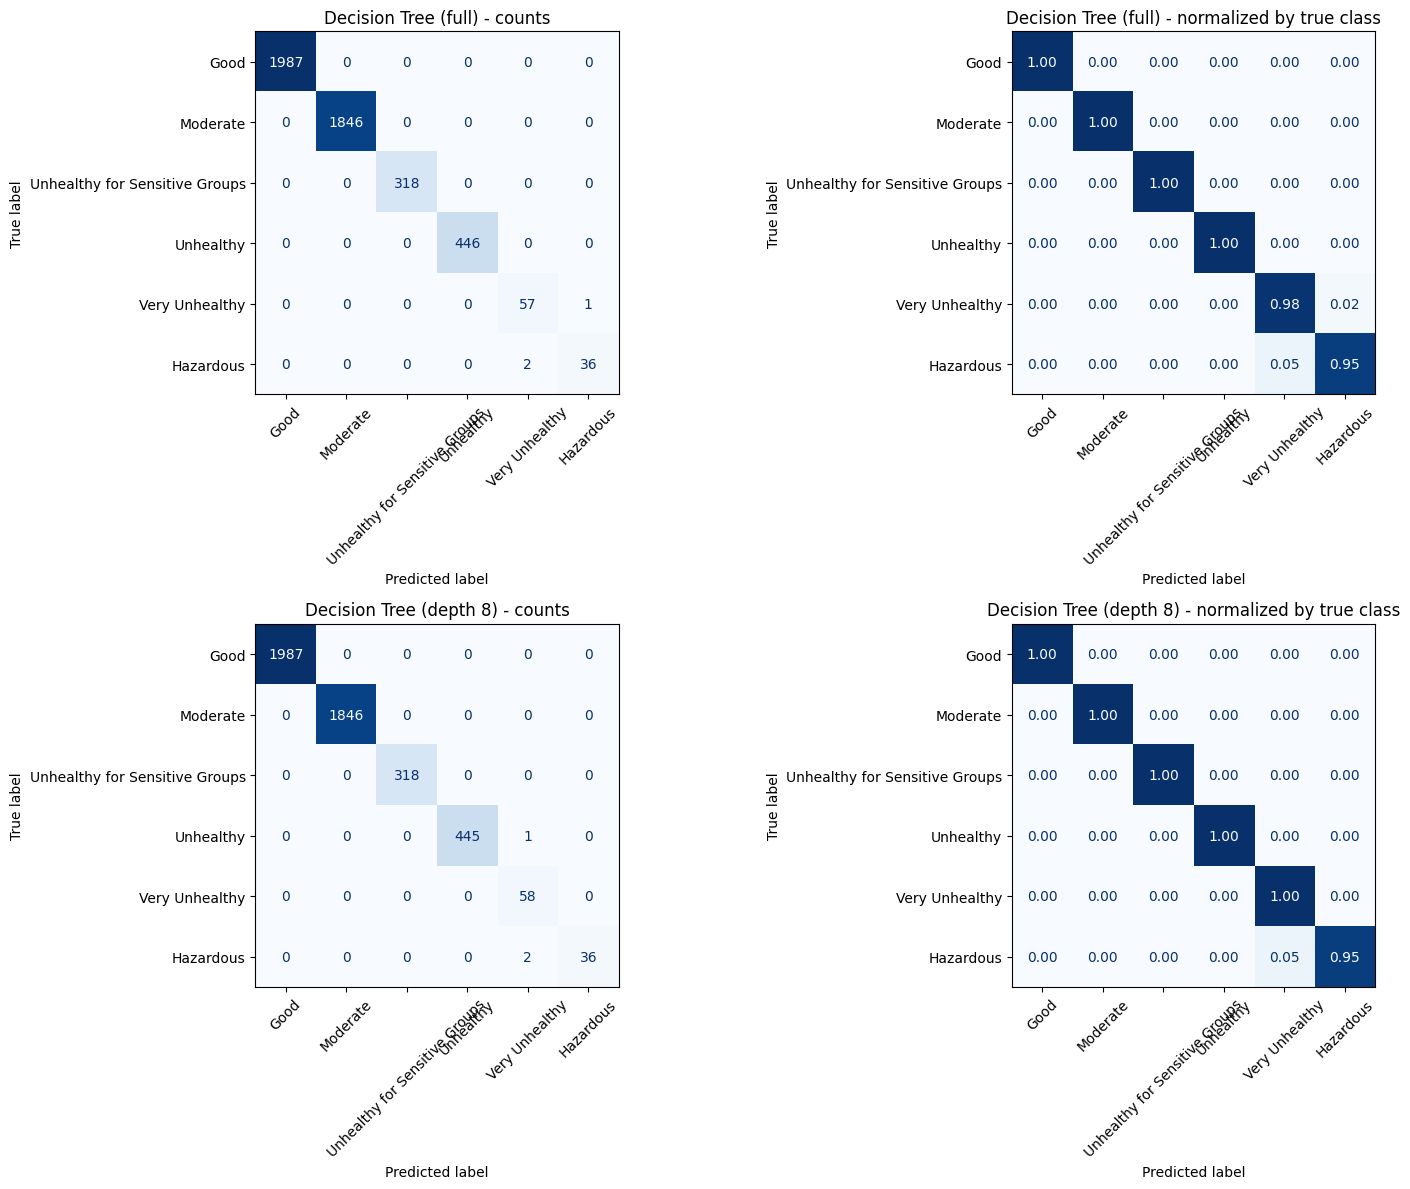

Feature importance (depth 8):
PM2.5 AQI Value    0.9312
Ozone AQI Value    0.0682
CO AQI Value       0.0006
NO2 AQI Value      0.0000
dtype: float64 

Depth-3 tree accuracy (test): 0.9729


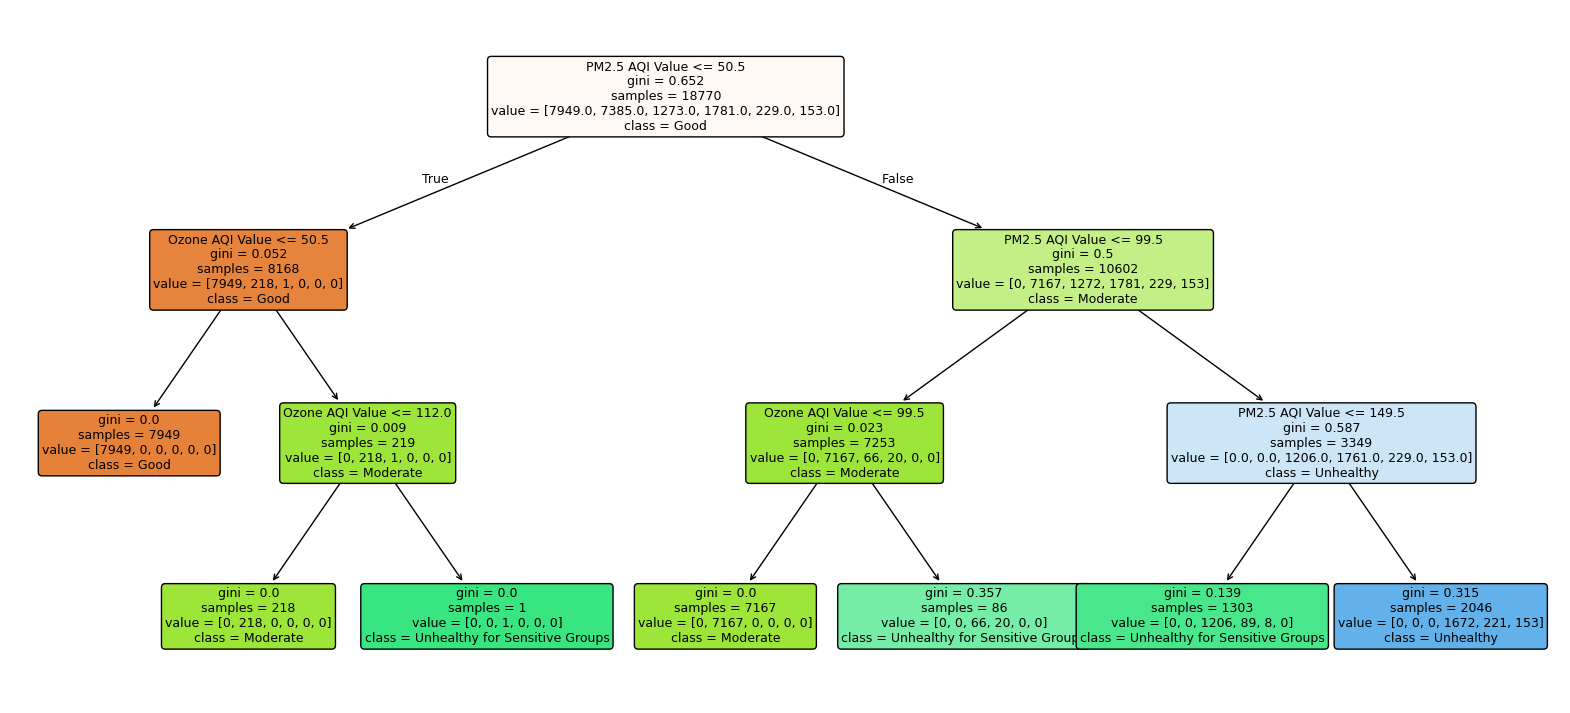

In [36]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# --- Entraînement (données d'origine) ---
dt_clf_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_clf_train)
dt_clf = DecisionTreeClassifier(max_depth=8, min_samples_leaf=10,
                                random_state=42).fit(X_train, y_clf_train)

models_dt = [("Decision Tree (full)", dt_clf_full),
             ("Decision Tree (depth 8)", dt_clf)]

preds_dt = {}
for name, model in models_dt:
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)
    preds_dt[name] = pred_te
    clf_results.append(evaluate_clf(name, y_clf_train, pred_tr, y_clf_test, pred_te))

print("Full tree: depth =", dt_clf_full.get_depth(), "| leaves =", dt_clf_full.get_n_leaves())
print("Constrained tree: depth =", dt_clf.get_depth(), "| leaves =", dt_clf.get_n_leaves(), "\n")

# --- Tableau récapitulatif (tous les classifieurs depuis le début) ---
print(pd.DataFrame(clf_results).set_index("Model").round(4), "\n")

# --- Rapports par classe, un par modèle ---
for name, _ in models_dt:
    print("=" * 70)
    print(name)
    print(classification_report(y_clf_test, preds_dt[name],
                                target_names=category_order, zero_division=0))

# --- Matrices de confusion (normalisées par classe réelle + counts) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for i, (name, _) in enumerate(models_dt):
    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds_dt[name], display_labels=category_order,
        ax=axes[i, 0], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes[i, 0].set_title(f"{name} - counts")
    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds_dt[name], display_labels=category_order,
        normalize="true", values_format=".2f",
        ax=axes[i, 1], cmap="Blues", colorbar=False, xticks_rotation=45)
    axes[i, 1].set_title(f"{name} - normalized by true class")
plt.tight_layout()
plt.show()

# --- Importance des variables (arbre contraint) ---
imp = pd.Series(dt_clf.feature_importances_, index=features).sort_values(ascending=False)
print("Feature importance (depth 8):")
print(imp.round(4), "\n")

# --- Arbre lisible : version réduite (profondeur 3) pour l'interprétabilité ---
dt_small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_clf_train)
print("Depth-3 tree accuracy (test):", round(accuracy_score(y_clf_test, dt_small.predict(X_test)), 4))

plt.figure(figsize=(20, 9))
plot_tree(dt_small, feature_names=features, class_names=category_order,
          filled=True, rounded=True, fontsize=9)
plt.show()

We trained a full tree (no constraint) and a constrained tree (`max_depth=8`, `min_samples_leaf=10`) on the original data.

**Results.**

| Model | Accuracy test | Macro-F1 | Recall Hazardous |
|---|---|---|---|
| Decision Tree (full) | 0.9994 | 0.9891 | 0.9474 |
| Decision Tree (depth 8) | 0.9994 | 0.9911 | 0.9474 |

**Observations.**
- Both trees are much better than Logistic Regression (accuracy 0.945, macro-F1 0.90). The categories are defined by thresholds on the AQI, which a tree can learn directly and a linear model cannot.
- Each tree makes only 3 errors on the 4693 test examples, all between `Very Unhealthy` and `Hazardous` (or their neighbour). The other classes are almost perfect.
- The full tree fits the training set perfectly (accuracy 1.00) but test accuracy is still 0.9994, so there is no real overfitting. It has only 26 leaves, because a few rules are enough to describe the classes.
- The constrained tree gives the same accuracy with a simpler model. The small macro-F1 difference comes from where the 3 errors fall, so it is not significant.
- `Hazardous` recall (0.947) is slightly lower than for Logistic Regression, but this is 1 or 2 examples out of 38.

**Feature importance.** PM2.5 (0.93) dominates, then Ozone (0.07). CO and NO2 are almost unused, as in the regression task.

**Interpretability.** The depth-3 tree uses PM2.5 thresholds of 50, 100 and 150, which are the official AQI boundaries, and Ozone thresholds of 50 and 100. The tree found the AQI rules by itself: the category is set by the dominant pollutant. At depth 3 the tree cannot separate the rare classes (test accuracy 0.973), so deeper trees are needed.

### 3.4 Random Forest

                                Accuracy train  Accuracy test  \
Model                                                           
Logistic Regression                     0.9388         0.9452   
Logistic Regression (balanced)          0.9245         0.9320   
Decision Tree (full)                    1.0000         0.9994   
Decision Tree (depth 8)                 0.9992         0.9994   
Random Forest                           1.0000         0.9994   
Random Forest (balanced)                1.0000         0.9996   

                                Precision (macro)  Recall (macro)  F1 (macro)  \
Model                                                                           
Logistic Regression                        0.9356          0.8824      0.9034   
Logistic Regression (balanced)             0.8521          0.9272      0.8799   
Decision Tree (full)                       0.9898          0.9884      0.9891   
Decision Tree (depth 8)                    0.9918          0.9909      0.9

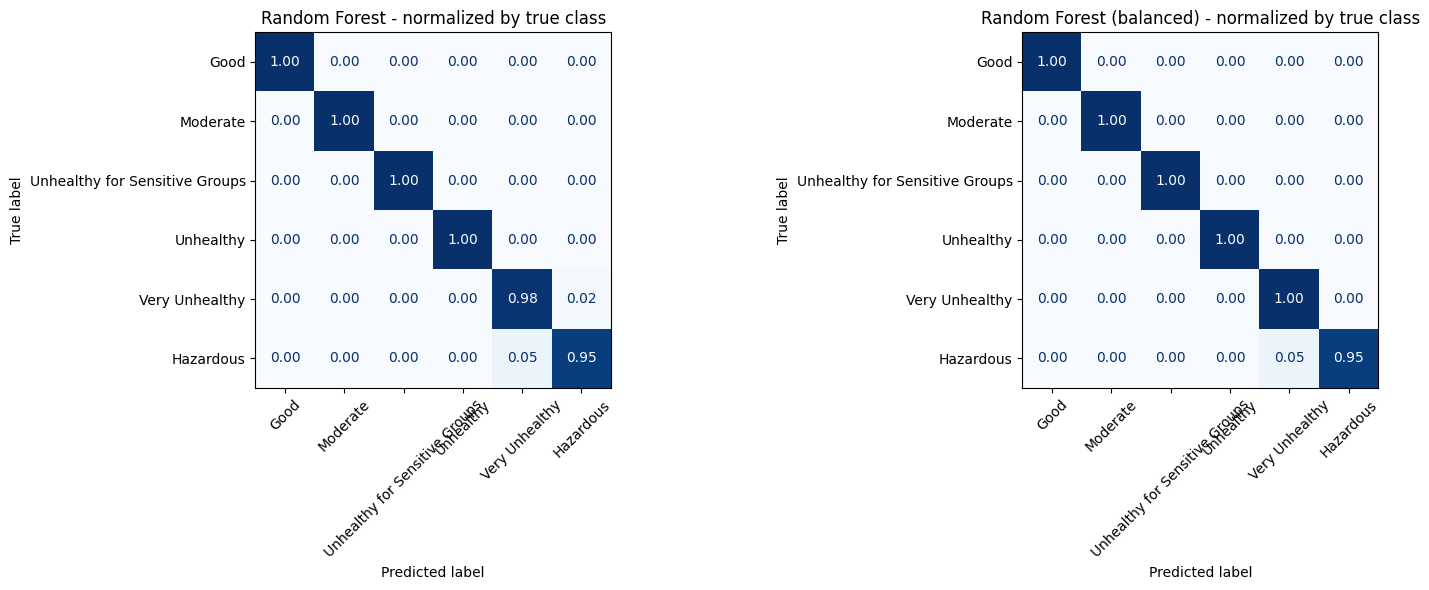


Feature importance (Random Forest):
PM2.5 AQI Value    0.8380
Ozone AQI Value    0.0796
CO AQI Value       0.0744
NO2 AQI Value      0.0080
dtype: float64


In [37]:
from sklearn.ensemble import RandomForestClassifier

# --- Entraînement (données d'origine) ---
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_clf_train)

rf_clf_bal = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                    random_state=42, n_jobs=-1)
rf_clf_bal.fit(X_train, y_clf_train)

models_rf = [("Random Forest", rf_clf),
             ("Random Forest (balanced)", rf_clf_bal)]

preds_rf = {}
for name, model in models_rf:
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)
    preds_rf[name] = pred_te
    clf_results.append(evaluate_clf(name, y_clf_train, pred_tr, y_clf_test, pred_te))

# --- Tableau récapitulatif (tous les classifieurs) ---
print(pd.DataFrame(clf_results).set_index("Model").round(4), "\n")

# --- Rapports par classe (un par modèle, pour éviter la troncature) ---
print("=" * 70)
print("Random Forest")
print(classification_report(y_clf_test, preds_rf["Random Forest"],
                            target_names=category_order, zero_division=0, digits=3))

# --- Erreurs détaillées : quelles lignes sont mal classées ? ---
for name, _ in models_rf:
    wrong = y_clf_test.index[preds_rf[name] != y_clf_test.values]
    err = X_test.loc[wrong].copy()
    err["True"] = y_clf_test.loc[wrong].map(dict(enumerate(category_order)))
    err["Predicted"] = pd.Series(preds_rf[name], index=y_clf_test.index).loc[wrong].map(dict(enumerate(category_order)))
    print(f"\nMisclassified examples - {name} ({len(wrong)} errors):")
    print(err)

# --- Matrices de confusion ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, _) in zip(axes, models_rf):
    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds_rf[name], display_labels=category_order,
        normalize="true", values_format=".2f",
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name} - normalized by true class")
plt.tight_layout()
plt.show()

# --- Importance des variables ---
imp_rf = pd.Series(rf_clf.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importance (Random Forest):")
print(imp_rf.round(4))

We trained a Random Forest of 200 trees on the original data, with and without `class_weight="balanced"`.

| Model | Accuracy test | Macro-F1 | Recall Hazardous |
|---|---|---|---|
| Random Forest | 0.9994 | 0.9891 | 0.9474 |
| Random Forest (balanced) | 0.9996 | 0.9927 | 0.9474 |

**Observations.**
- The forest gives the same scores as the single decision tree. The tree was already almost perfect, so averaging many trees brings no measurable gain here.
- The balanced version makes 2 errors instead of 3. This is a difference of one example, so it is not significant.
- The remaining errors are 2 `Hazardous` cases predicted as `Very Unhealthy`. They are the same in all tree-based models.
- There is no overfitting: train accuracy is 1.00 and test accuracy is 0.9994.

**Feature importance.** PM2.5 dominates (0.84), then Ozone (0.08). CO gets a higher importance than in the single tree (0.07), probably because the trees split on different correlated variables. Impurity-based importance should be interpreted with care.

### 3.5 Perceptron

                                Accuracy train  Accuracy test  \
Model                                                           
Logistic Regression                     0.9388         0.9452   
Logistic Regression (balanced)          0.9245         0.9320   
Decision Tree (full)                    1.0000         0.9994   
Decision Tree (depth 8)                 0.9992         0.9994   
Random Forest                           1.0000         0.9994   
Random Forest (balanced)                1.0000         0.9996   
Perceptron                              0.7623         0.7628   
Perceptron (balanced)                   0.5053         0.5029   

                                Precision (macro)  Recall (macro)  F1 (macro)  \
Model                                                                           
Logistic Regression                        0.9356          0.8824      0.9034   
Logistic Regression (balanced)             0.8521          0.9272      0.8799   
Decision Tree (full)     

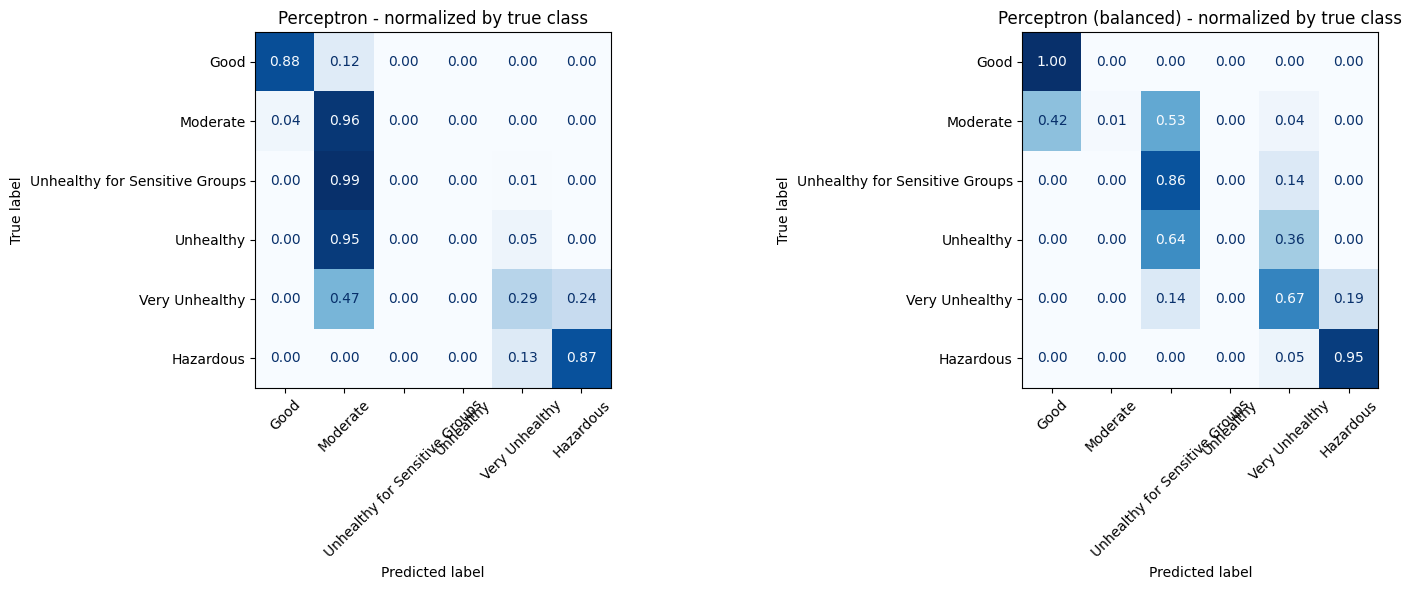

Iterations used: 15 (standard) | 10 (balanced)


In [38]:
from sklearn.linear_model import Perceptron

# --- Entraînement (données normalisées) ---
per_std = Perceptron(max_iter=1000, tol=1e-3, random_state=42)
per_std.fit(X_train_scaled, y_clf_train)

per_bal = Perceptron(max_iter=1000, tol=1e-3, class_weight="balanced", random_state=42)
per_bal.fit(X_train_scaled, y_clf_train)

models_per = [("Perceptron", per_std),
              ("Perceptron (balanced)", per_bal)]

preds_per = {}
for name, model in models_per:
    pred_tr = model.predict(X_train_scaled)
    pred_te = model.predict(X_test_scaled)
    preds_per[name] = pred_te
    clf_results.append(evaluate_clf(name, y_clf_train, pred_tr, y_clf_test, pred_te))

# --- Tableau récapitulatif (tous les classifieurs) ---
print(pd.DataFrame(clf_results).set_index("Model").round(4), "\n")

# --- Rapports par classe (un par cellule de sortie pour éviter la troncature) ---
print("=" * 70)
print("Perceptron")
print(classification_report(y_clf_test, preds_per["Perceptron"],
                            target_names=category_order, zero_division=0, digits=3))
print("=" * 70)
print("Perceptron (balanced)")
print(classification_report(y_clf_test, preds_per["Perceptron (balanced)"],
                            target_names=category_order, zero_division=0, digits=3))

# --- Matrices de confusion ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, _) in zip(axes, models_per):
    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds_per[name], display_labels=category_order,
        normalize="true", values_format=".2f",
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name} - normalized by true class")
plt.tight_layout()
plt.show()

# --- Convergence : nombre d'itérations utilisées ---
print("Iterations used:", per_std.n_iter_, "(standard) |", per_bal.n_iter_, "(balanced)")

We trained a Perceptron (a single linear neuron) on the standardized data, with and without `class_weight="balanced"`.

| Model | Accuracy test | Macro-F1 | Macro recall |
|---|---|---|---|
| Perceptron | 0.7628 | 0.4640 | 0.5011 |
| Perceptron (balanced) | 0.5029 | 0.3686 | 0.5829 |

**Observations.**
- The Perceptron is the weakest model so far, far below Logistic Regression (accuracy 0.945, macro-F1 0.90).
- Train and test scores are almost equal but low, so the model underfits (high bias). It is also unstable: it stopped after only 15 and 10 iterations without reaching a good solution.
- The standard Perceptron predicts almost everything as `Moderate`. `Unhealthy for Sensitive Groups` and `Unhealthy` are never recognized (recall 0.00).
- `class_weight="balanced"` makes it worse: accuracy drops to 0.50 and the errors are larger (for example `Moderate` predicted as `Good`).

**Why.** Like Logistic Regression, the Perceptron uses linear boundaries, but its update rule oscillates when classes overlap, while Logistic Regression optimizes a smooth loss. The middle classes cannot be isolated by a single line. Results may also depend on the data order and the random seed.

**Conclusion.** A single linear neuron is not suitable for this task. A non-linear model is needed, which leads to the MLP.

### 3.6 MLP Classifier

                                Accuracy train  Accuracy test  \
Model                                                           
Logistic Regression                     0.9388         0.9452   
Logistic Regression (balanced)          0.9245         0.9320   
Decision Tree (full)                    1.0000         0.9994   
Decision Tree (depth 8)                 0.9992         0.9994   
Random Forest                           1.0000         0.9994   
Random Forest (balanced)                1.0000         0.9996   
Perceptron                              0.7623         0.7628   
Perceptron (balanced)                   0.5053         0.5029   
MLP (16)                                0.9784         0.9772   
MLP (64, 32)                            0.9920         0.9900   

                                Precision (macro)  Recall (macro)  F1 (macro)  \
Model                                                                           
Logistic Regression                        0.9356        

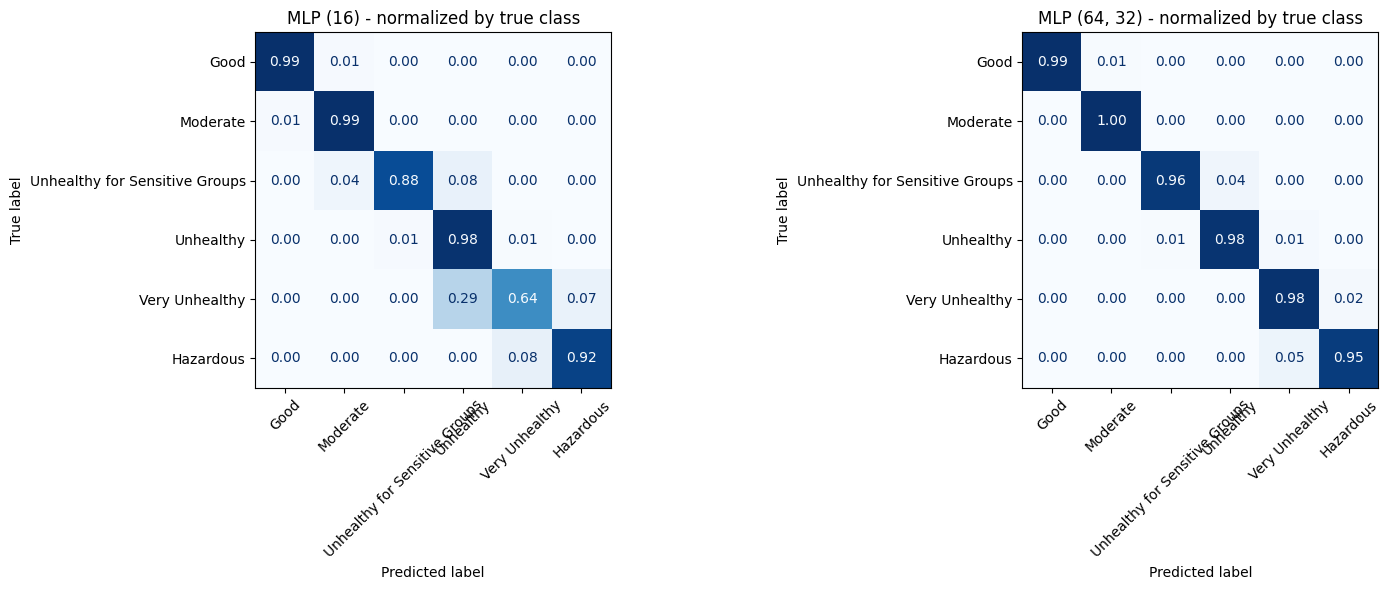

Iterations used: 120 (16) | 38 (64, 32)


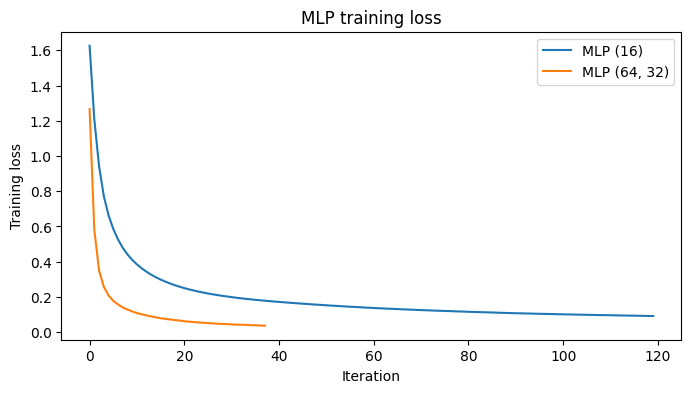

In [39]:
from sklearn.neural_network import MLPClassifier

# --- Entraînement (données normalisées) ---
mlp_small = MLPClassifier(hidden_layer_sizes=(16,), max_iter=500,
                          early_stopping=True, random_state=42)
mlp_small.fit(X_train_scaled, y_clf_train)

mlp_big = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                        early_stopping=True, random_state=42)
mlp_big.fit(X_train_scaled, y_clf_train)

models_mlp = [("MLP (16)", mlp_small),
              ("MLP (64, 32)", mlp_big)]

preds_mlp = {}
for name, model in models_mlp:
    pred_tr = model.predict(X_train_scaled)
    pred_te = model.predict(X_test_scaled)
    preds_mlp[name] = pred_te
    clf_results.append(evaluate_clf(name, y_clf_train, pred_tr, y_clf_test, pred_te))

# --- Tableau récapitulatif (tous les classifieurs) ---
print(pd.DataFrame(clf_results).set_index("Model").round(4), "\n")

# --- Rapports par classe (un par modèle) ---
for name, _ in models_mlp:
    print("=" * 70)
    print(name)
    print(classification_report(y_clf_test, preds_mlp[name],
                                target_names=category_order, zero_division=0, digits=3))

# --- Matrices de confusion ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, _) in zip(axes, models_mlp):
    ConfusionMatrixDisplay.from_predictions(
        y_clf_test, preds_mlp[name], display_labels=category_order,
        normalize="true", values_format=".2f",
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name} - normalized by true class")
plt.tight_layout()
plt.show()

# --- Convergence : itérations utilisées et courbe de loss ---
print("Iterations used:", mlp_small.n_iter_, "(16) |", mlp_big.n_iter_, "(64, 32)")

plt.figure(figsize=(8, 4))
plt.plot(mlp_small.loss_curve_, label="MLP (16)")
plt.plot(mlp_big.loss_curve_, label="MLP (64, 32)")
plt.xlabel("Iteration")
plt.ylabel("Training loss")
plt.title("MLP training loss")
plt.legend()
plt.show()

We trained two MLPs on the standardized data, one small (16 neurons) and one larger (64, 32), with early stopping.

| Model | Accuracy test | Macro-F1 | Macro recall |
|---|---|---|---|
| MLP (16) | 0.9772 | 0.9147 | 0.9001 |
| MLP (64, 32) | 0.9900 | 0.9680 | 0.9760 |

**Observations.**
- Both MLPs are much better than the linear models (Logistic Regression: accuracy 0.945, Perceptron: 0.763). The hidden layers let the network learn non-linear boundaries.
- Model complexity helps here. The larger network improves macro-F1 from 0.915 to 0.968, mainly on `Very Unhealthy` (recall from 0.64 to 0.98). The small network still has some bias and has the same weakness as Logistic Regression on this class.
- There is no overfitting: train and test accuracy are very close. Training loss decreases smoothly and early stopping ended training before the maximum number of iterations.
- The decision tree and the random forest are still slightly better (accuracy 0.9994). The true rules are sharp thresholds, which trees represent exactly, while a neural network approximates them with smooth curves.
- The remaining errors are between neighbouring classes, unlike the Perceptron.

**Conclusion.** The MLP is a good non-linear model, but it needs standardized data and tuning, and it is harder to interpret than a tree. Here a simple tree gives better results.

### 3.7 Comparison of the Classifiers

                                Accuracy test  F1 (macro)  Recall (macro)  \
Model                                                                       
Random Forest (balanced)               0.9996      0.9927          0.9912   
Decision Tree (depth 8)                0.9994      0.9911          0.9909   
Decision Tree (full)                   0.9994      0.9891          0.9884   
Random Forest                          0.9994      0.9891          0.9884   
MLP (64, 32)                           0.9900      0.9680          0.9760   
MLP (16)                               0.9772      0.9147          0.9001   
Logistic Regression                    0.9452      0.9034          0.8824   
Logistic Regression (balanced)         0.9320      0.8799          0.9272   
Perceptron                             0.7628      0.4640          0.5011   
Perceptron (balanced)                  0.5029      0.3686          0.5829   

                                Errors (test)  Gap (train - test)  
Model  

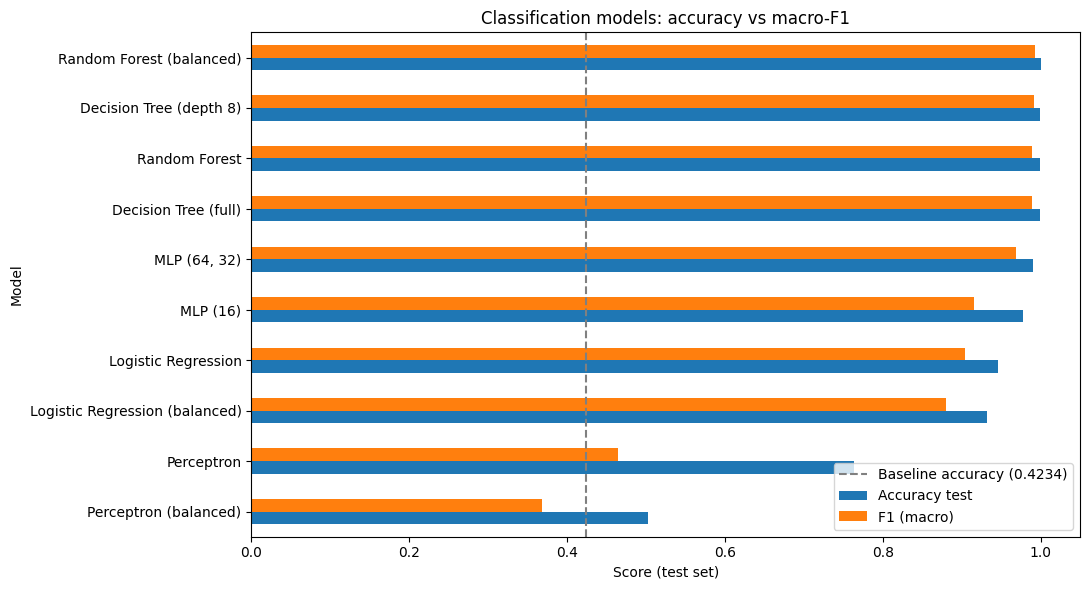

Recall per class (test):
                                 Good  Moderate  \
Model                                             
Random Forest (balanced)        1.000     1.000   
Decision Tree (depth 8)         1.000     1.000   
Decision Tree (full)            1.000     1.000   
Random Forest                   1.000     1.000   
MLP (64, 32)                    0.993     0.996   
MLP (16)                        0.991     0.990   
Logistic Regression             0.952     0.967   
Logistic Regression (balanced)  0.945     0.937   
Perceptron                      0.880     0.965   
Perceptron (balanced)           0.998     0.014   

                                Unhealthy for Sensitive Groups  Unhealthy  \
Model                                                                       
Random Forest (balanced)                                 1.000      1.000   
Decision Tree (depth 8)                                  1.000      0.998   
Decision Tree (full)                                  

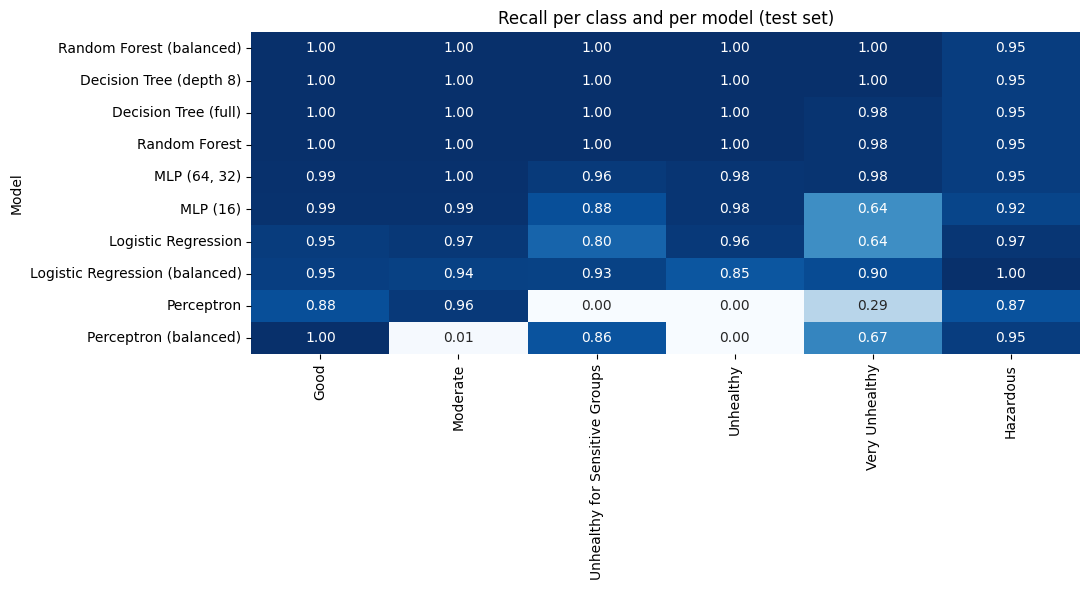

In [41]:
# --- 1. Tableau récapitulatif trié par macro-F1 ---
comp = pd.DataFrame(clf_results).set_index("Model")
comp["Errors (test)"] = ((1 - comp["Accuracy test"]) * len(y_clf_test)).round().astype(int)
comp["Gap (train - test)"] = comp["Accuracy train"] - comp["Accuracy test"]
comp = comp.sort_values("F1 (macro)", ascending=False)
print(comp[["Accuracy test", "F1 (macro)", "Recall (macro)",
            "Errors (test)", "Gap (train - test)"]].round(4), "\n")

# --- 2. Graphique : accuracy et macro-F1 ---
fig, ax = plt.subplots(figsize=(11, 6))
comp[["Accuracy test", "F1 (macro)"]].sort_values("F1 (macro)").plot.barh(ax=ax)
ax.axvline(0.4234, color="gray", linestyle="--", label="Baseline accuracy (0.4234)")
ax.set_xlabel("Score (test set)")
ax.set_title("Classification models: accuracy vs macro-F1")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# --- 3. Recall par classe pour chaque modèle ---
all_models = {
    "Logistic Regression": log_std, "Logistic Regression (balanced)": log_bal,
    "Decision Tree (full)": dt_clf_full, "Decision Tree (depth 8)": dt_clf,
    "Random Forest": rf_clf, "Random Forest (balanced)": rf_clf_bal,
    "Perceptron": per_std, "Perceptron (balanced)": per_bal,
    "MLP (16)": mlp_small, "MLP (64, 32)": mlp_big,
}
scaled_models = {"Logistic Regression", "Logistic Regression (balanced)",
                 "Perceptron", "Perceptron (balanced)", "MLP (16)", "MLP (64, 32)"}

recall_table = {}
for name, model in all_models.items():
    Xt = X_test_scaled if name in scaled_models else X_test
    recall_table[name] = recall_score(y_clf_test, model.predict(Xt),
                                      average=None, labels=range(6), zero_division=0)
recall_df = pd.DataFrame(recall_table, index=category_order).T
print("Recall per class (test):")
print(recall_df.loc[comp.index].round(3))

plt.figure(figsize=(11, 6))
sns.heatmap(recall_df.loc[comp.index], annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=1, cbar=False)
plt.title("Recall per class and per model (test set)")
plt.tight_layout()
plt.show()

| Model | Accuracy test | Macro-F1 | Errors (test) |
|---|---|---|---|
| Random Forest (balanced) | 0.9996 | 0.9927 | 2 |
| Decision Tree (depth 8) | 0.9994 | 0.9911 | 3 |
| Decision Tree (full) | 0.9994 | 0.9891 | 3 |
| Random Forest | 0.9994 | 0.9891 | 3 |
| MLP (64, 32) | 0.9900 | 0.9680 | 47 |
| MLP (16) | 0.9772 | 0.9147 | 107 |
| Logistic Regression | 0.9452 | 0.9034 | 257 |
| Logistic Regression (balanced) | 0.9320 | 0.8799 | 319 |
| Perceptron | 0.7628 | 0.4640 | 1113 |
| Perceptron (balanced) | 0.5029 | 0.3686 | 2333 |

**Performance.**
- There are three groups: tree-based models (2 to 3 errors), MLPs (47 to 107 errors) and linear models (257 or more errors).
- The differences between the four tree-based models are one example out of 4693, so they are not significant.
- No model overfits: the gap between train and test accuracy is below 0.01. The weaker models suffer from bias (underfitting), not variance.
- Accuracy alone is misleading: the Perceptron reaches 0.76 accuracy but only 0.46 macro-F1.

**Rare classes.** `Very Unhealthy` separates the models best: recall is 0.98 to 1.00 for trees and the larger MLP, 0.64 for Logistic Regression and the small MLP, and 0.29 for the Perceptron. For `Hazardous`, most models are between 0.87 and 1.00, but with only 38 examples one case changes the score by 0.026. `class_weight="balanced"` helps linear models on rare classes but lowers precision, and it changes nothing measurable for trees.

**Interpretability.**

| Model | Interpretability | Why |
|---|---|---|
| Decision Tree | Very high | Readable rules (PM2.5 thresholds at 50, 100, 150) |
| Logistic Regression | High | One coefficient per variable |
| Perceptron | Medium | Readable weights, but unstable results |
| Random Forest | Medium | 200 trees, only global importance is readable |
| MLP | Low | Hidden layers, black box |

**Conclusion.** The decision tree is both the most interpretable and among the most accurate models, because the AQI category is defined by thresholds on the sub-indexes. Complexity helps only up to a point: it matters from linear models to MLP to trees, but a more complex forest adds nothing over a single tree.

## 4. Conclusion

### Best models

| Task | Best model | Key results (test set) |
|---|---|---|
| Regression (`AQI Value`) | Random Forest | R² = 0.998, RMSE = 2.58, MAE = 0.22 |
| Classification (`AQI Category`) | Decision Tree / Random Forest | Accuracy ≈ 0.999, macro-F1 ≈ 0.99 (2–3 errors out of 4,693) |

For classification, the top four models are statistically indistinguishable (a difference of one example). The depth-8 Decision Tree is the best trade-off: as accurate as the forests, but much simpler and readable.

### Strengths and limitations

| Model | Strengths | Limitations |
|---|---|---|
| Linear / Logistic Regression | Simple, fast, interpretable | High bias: cannot represent a maximum or sharp thresholds (R² = 0.972, macro-F1 = 0.90) |
| Decision Tree | Very interpretable; it recovered the official AQI thresholds (50, 100, 150) on its own | Fully grown regression tree memorizes the training set (high variance) |
| Random Forest | Lowest regression RMSE (fewer large errors thanks to averaging) | Less interpretable; no real gain over a single tree in classification |
| Perceptron | Very simple | Worst model (macro-F1 = 0.46): classes are not linearly separable, so training is unstable |
| MLP | Learns non-linear boundaries (macro-F1 = 0.97 with two hidden layers) | Black box; still below the trees |

Common limitations: all models are less accurate for AQI > 300 and for the rare classes `Very Unhealthy` and `Hazardous` (few examples, and the AQI seems to be computed differently for extreme PM2.5 values). The recall of these classes is noisy, since one example in the test set changes it by 0.02–0.03.

### Influence of model complexity

Performance improved as the models became more flexible (linear → MLP → tree/forest), because the main limitation was **bias**, not variance. The AQI is the maximum of the sub-indexes, and the categories are defined by fixed thresholds: models that can learn thresholds fit this perfectly. Train and test scores were close almost everywhere, so there was no harmful overfitting. Complexity is not always useful: a forest did not beat a single tree in classification, and the MLP needed two hidden layers to reach good results.

### Reflections and recommendations

- **These scores do not reflect real forecasting.** The target is almost a deterministic function of the sub-indexes given as inputs. In practice, the AQI should simply be computed with the official formula (maximum of the sub-indexes).
- **ML becomes useful for real prediction.** It would require raw pollutant concentrations, weather, time and location data, in order to forecast future air quality or fill in missing measurements.
- **Choose according to the cost of errors.** If missing a dangerous episode is worse than a false alarm, use